Environment Setup & Imports

In [ ]:
!pip install -q scikit-image albumentations tf-keras-vis

import os, sys, random, warnings, json, time, re
from pathlib import Path
from collections import Counter, defaultdict
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from skimage.feature import hog, local_binary_pattern

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, f1_score,
    accuracy_score, average_precision_score,
    precision_recall_curve
)
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, Input, regularizers
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)

from tensorflow.keras.applications.convnext import preprocess_input as convnext_preprocess

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# ── Style ────────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "figure.dpi": 120, "font.family": "DejaVu Sans",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "figure.facecolor": "white"
})
PAL = ["#2E86AB", "#E84855", "#3BB273", "#F4A261", "#9B5DE5", "#FEE440"]

gpus = tf.config.list_physical_devices("GPU")
print(f"TensorFlow {tf.__version__}")
print(f"GPU: {gpus or 'None — CPU mode'}")
print(f"Using ConvNeXt preprocess_input (correct for ConvNeXtTiny backbone)")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.5/52.5 kB 2.2 MB/s eta 0:00:00
✅ TensorFlow 2.20.0
✅ GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ Using ConvNeXt preprocess_input (correct for ConvNeXtTiny backbone)


Mount Google Drive & Configuration

In [ ]:
import os
from google.colab import drive
drive.mount("/content/gdrive", force_remount=True)

BASE_DIR = Path("") -- Put in your own path
DATASET_ROOT = BASE_DIR / "dataset"

# ── Training config ──────────────────────────────────────────────────────────
IMG_SIZE        = 224        # ConvNeXtTiny / EfficientNetB0 optimal
BATCH_SIZE      = 16         # Small — dataset is tiny (1,708 images)
EPOCHS_WARMUP   = 20         # Phase 1: backbone frozen
EPOCHS_FINETUNE = 40         # Phase 2: unfreeze top layers
LR_WARMUP       = 1e-4
LR_FINETUNE     = 5e-6       # Very low for fine-tune
DROPOUT         = 0.4
HOG_PIX         = 8
LABEL_SMOOTHING = 0.1        # Helps with overconfident softmax on small data

# ── Output directory ─────────────────────────────────────────────────────────
OUT = Path(BASE_DIR / "data")
OUT.mkdir(parents=True, exist_ok=True)

# ── Canonical task-name map (FIX for typos in folder names) ──────────────────
TASK_CANONICAL = {
    "coloring"    : "Coloring",
    "colouring"   : "Coloring",
    "drawing"     : "Drawing",
    "handwriting" : "Handwriting",
    "handwritng"  : "Handwriting",
    "handwriitng" : "Handwriting",
    "handwritting": "Handwriting",
    "hand writing": "Handwriting",
}

def canonical_task(raw):
    return TASK_CANONICAL.get(raw.strip().lower(), raw.strip())

print(f"Config ready | Dataset root: {DATASET_ROOT}")
print(f"   IMG_SIZE={IMG_SIZE} | BATCH={BATCH_SIZE} | LR_warmup={LR_WARMUP}")

Mounted at /content/gdrive
✅ Config ready | Dataset root: /content/gdrive/MyDrive/ColabNotebooks/NEP2022PROJECTS/ASD/dataset
   IMG_SIZE=224 | BATCH=16 | LR_warmup=0.0001


Dataset Discovery & Typo Cleaning

In [ ]:

def walk_dataset(root):
    """
    Walk 4-level hierarchy:
      root / diagnosis / severity / age_group / task / images
    Returns a clean DataFrame with canonical labels.
    """
    IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tiff", ".webp"}
    records  = []
    root = Path(root)

    for diag_dir in sorted(root.iterdir()):
        if not diag_dir.is_dir(): continue
        diag_label = diag_dir.name.replace(" ", "_")   # "ASD with CD" → "ASD_with_CD"

        for sev_dir in sorted(diag_dir.iterdir()):
            if not sev_dir.is_dir(): continue
            sev_label = sev_dir.name.strip()           # Mild / Moderate / Severe / Normal

            for age_dir in sorted(sev_dir.iterdir()):
                if not age_dir.is_dir(): continue
                age_label = age_dir.name.strip()       # 3-6 years / 6-9 years / 9-12 years

                for task_dir in sorted(age_dir.iterdir()):
                    if not task_dir.is_dir(): continue
                    raw_task   = task_dir.name
                    task_label = canonical_task(raw_task)  #  FIX typos

                    for img_path in sorted(task_dir.iterdir()):
                        if img_path.suffix.lower() in IMG_EXTS:
                            records.append({
                                "path"     : str(img_path),
                                "diagnosis": diag_label,
                                "severity" : sev_label,
                                "age_group": age_label,
                                "task"     : task_label,
                                "raw_task" : raw_task,  # keep original for debug
                            })
    return pd.DataFrame(records)

df = walk_dataset(DATASET_ROOT)
assert len(df) > 0, f" No images found under {DATASET_ROOT} — check path!"

print(f"Total images: {len(df):,}")
print("\n── Diagnosis ──")
print(df["diagnosis"].value_counts().to_string())
print("\n── Severity ──")
print(df["severity"].value_counts().to_string())
print("\n── Age group ──")
print(df["age_group"].value_counts().to_string())
print("\n── Task (after cleaning) ──")
print(df["task"].value_counts().to_string())
print("\n── Raw task names found (before cleaning) ──")
print(df["raw_task"].value_counts().to_string())

✅ Total images: 1,708

── Diagnosis ──
diagnosis
ASD            572
ASD_with_CD    571
Non-ASD        565

── Severity ──
severity
Normal      565
Mild        384
Moderate    381
Severe      378

── Age group ──
age_group
9-12 years    572
6-9 years     569
3-6 years     567

── Task (after cleaning) ──
task
Drawing        571
Handwriting    569
Coloring       568

── Raw task names found (before cleaning) ──
raw_task
Drawing        571
Coloring       568
Handwriting    548
Handwritng      21


Exploratory Data Analysis

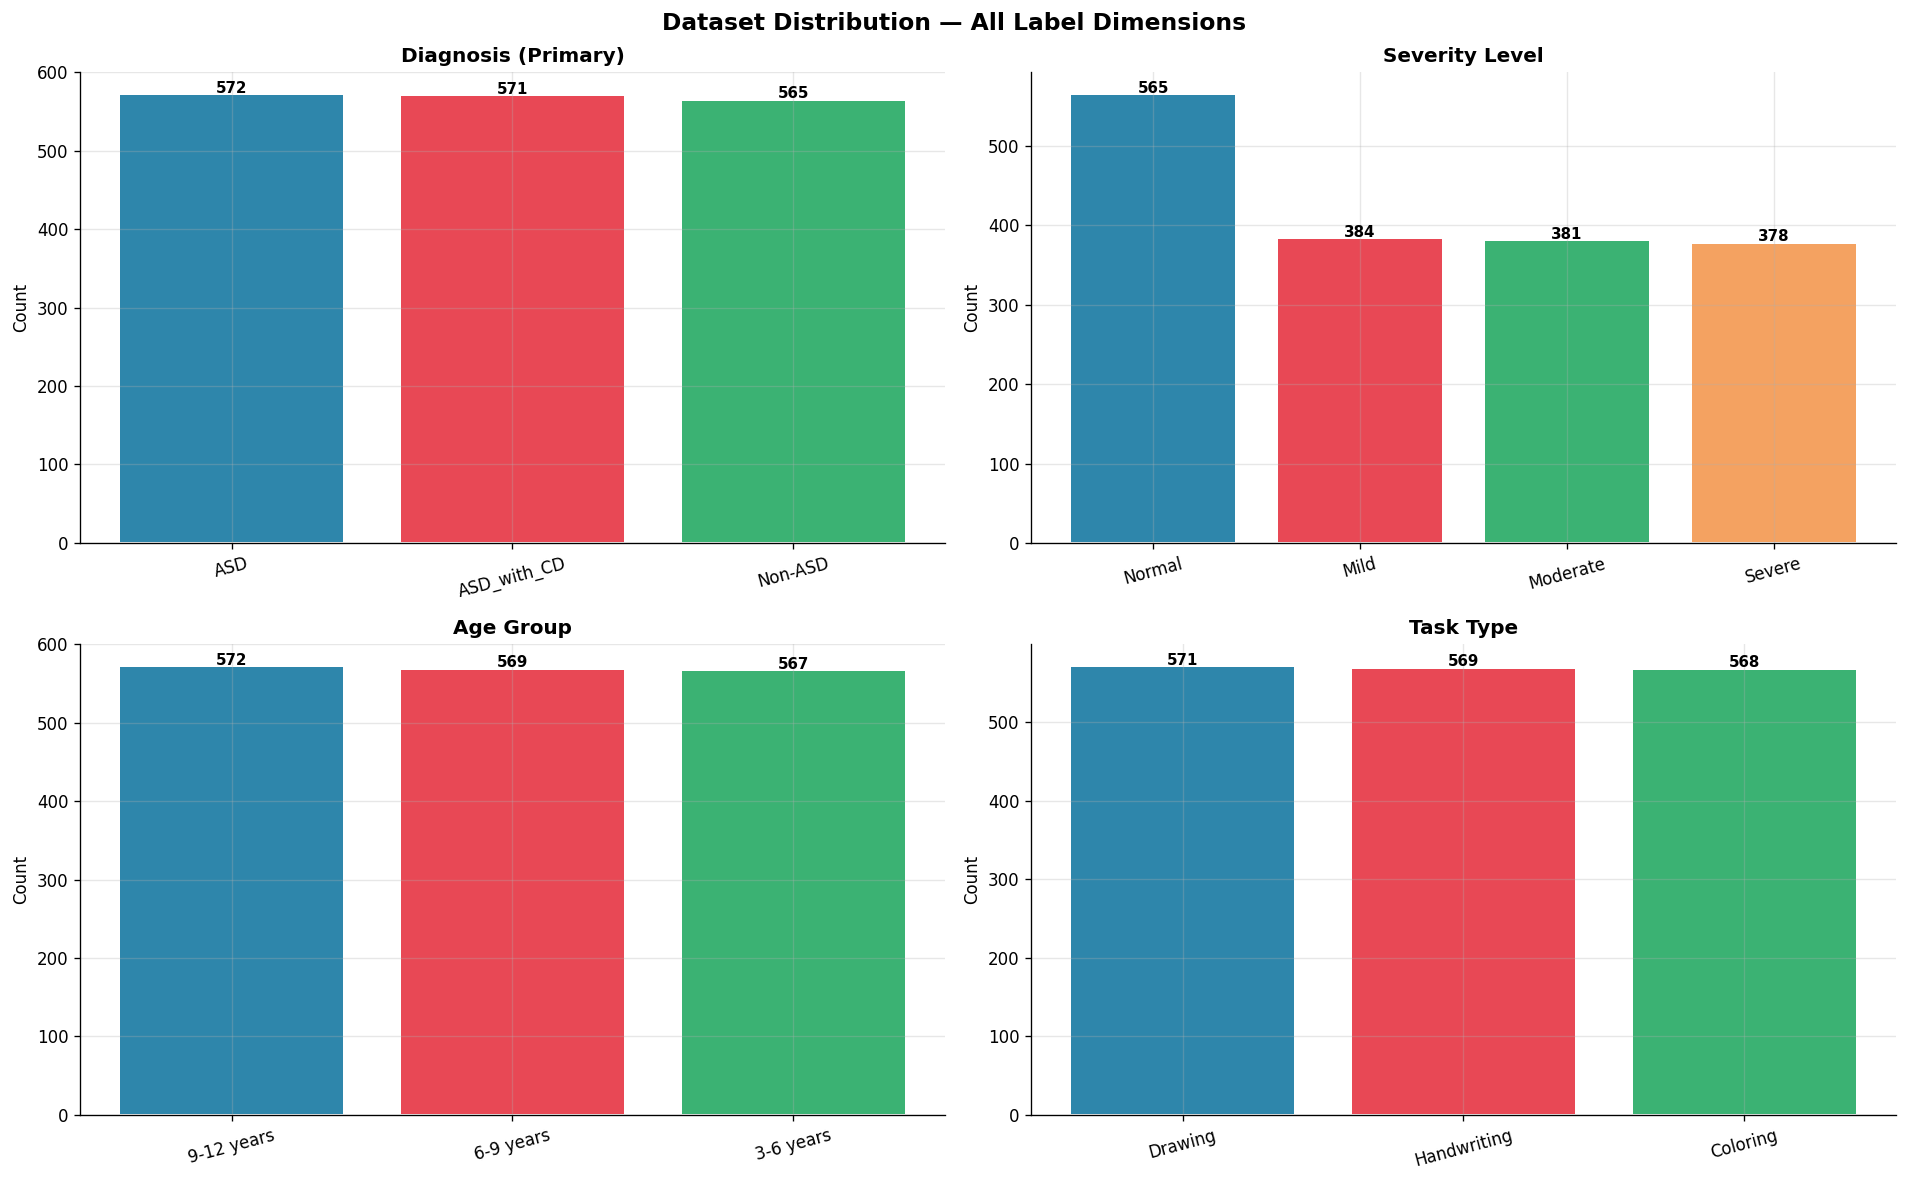

✅ 01_distributions.png


In [ ]:
# ── 4a. Distribution across all 4 label dimensions ──────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Dataset Distribution — All Label Dimensions", fontsize=14, fontweight="bold")

for ax, col, title, pal in zip(
        axes.flat,
        ["diagnosis", "severity", "age_group", "task"],
        ["Diagnosis (Primary)", "Severity Level", "Age Group", "Task Type"],
        [PAL[:3], PAL[:4], PAL[:3], PAL[:3]]):
    counts = df[col].value_counts()
    bars = ax.bar(counts.index, counts.values, color=pal[:len(counts)],
                  edgecolor="white", linewidth=1.2)
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("Count")
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 2,
                f"{v:,}", ha="center", fontsize=9, fontweight="bold")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig(OUT/"01_distributions.png", bbox_inches="tight")
plt.show()
print("01_distributions.png")

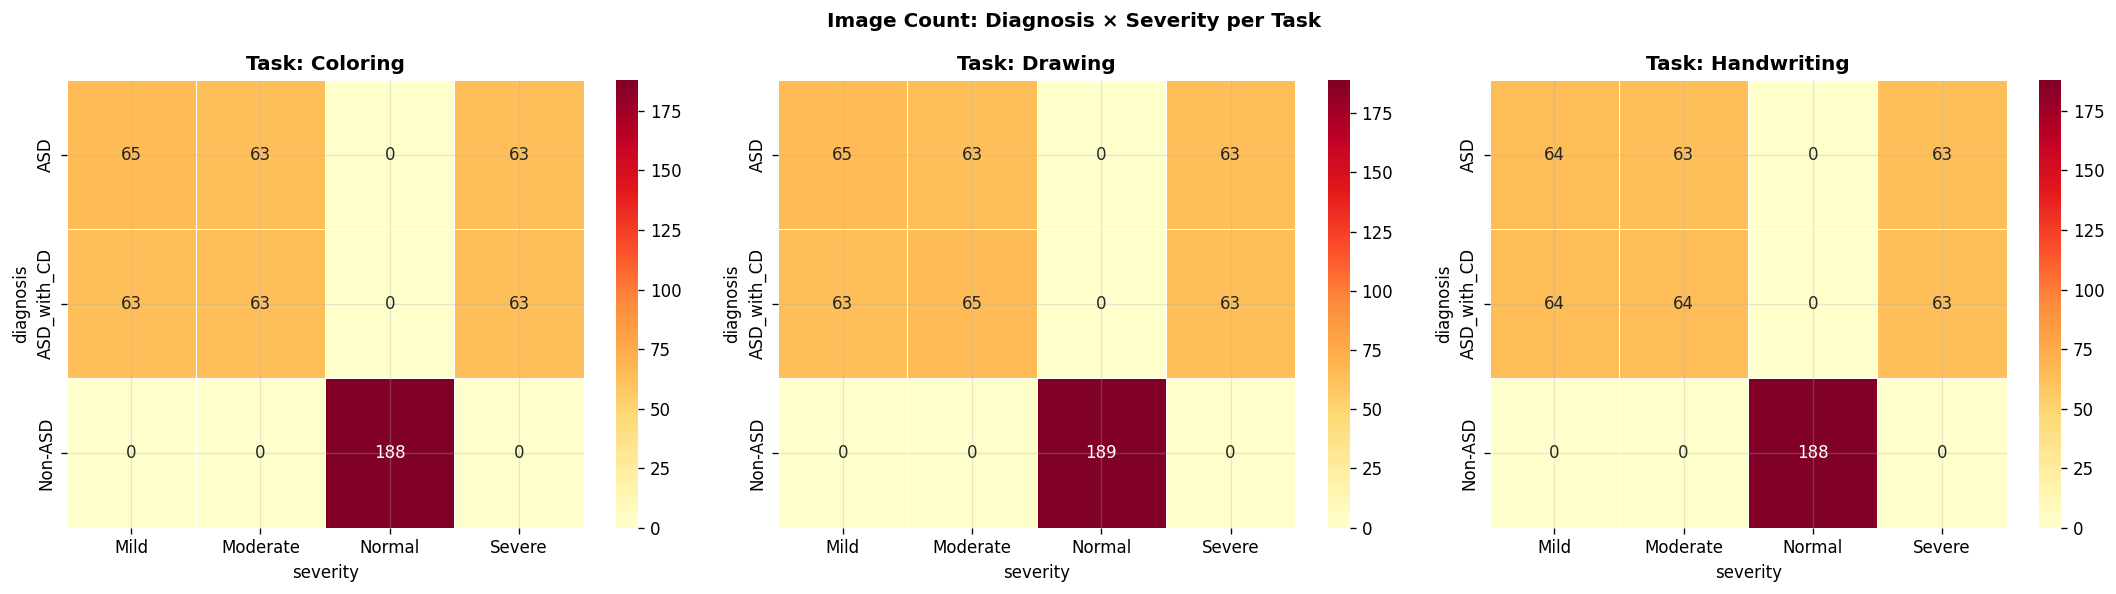

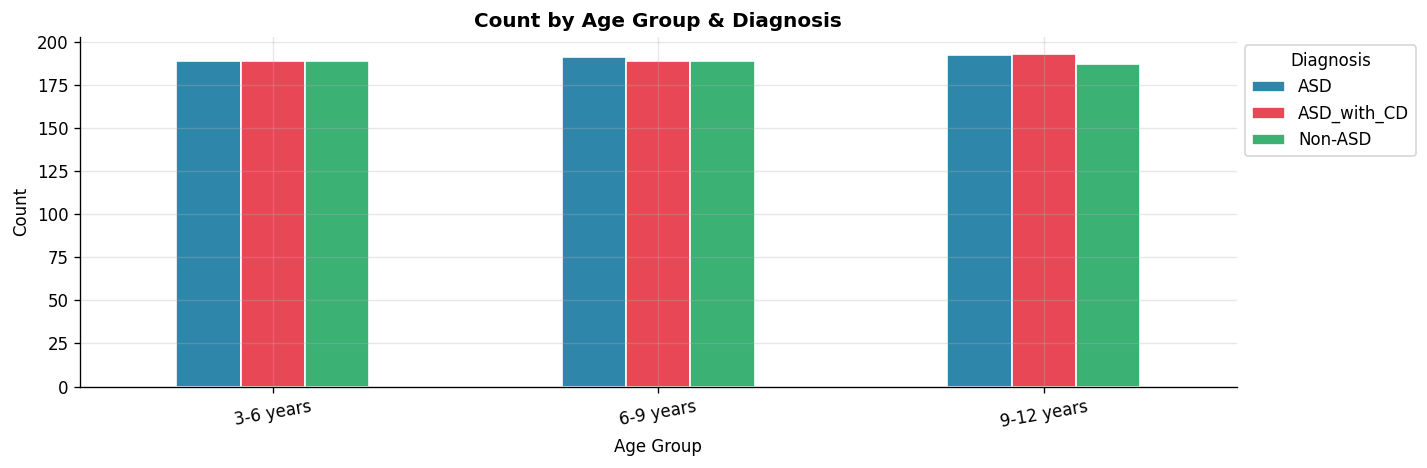

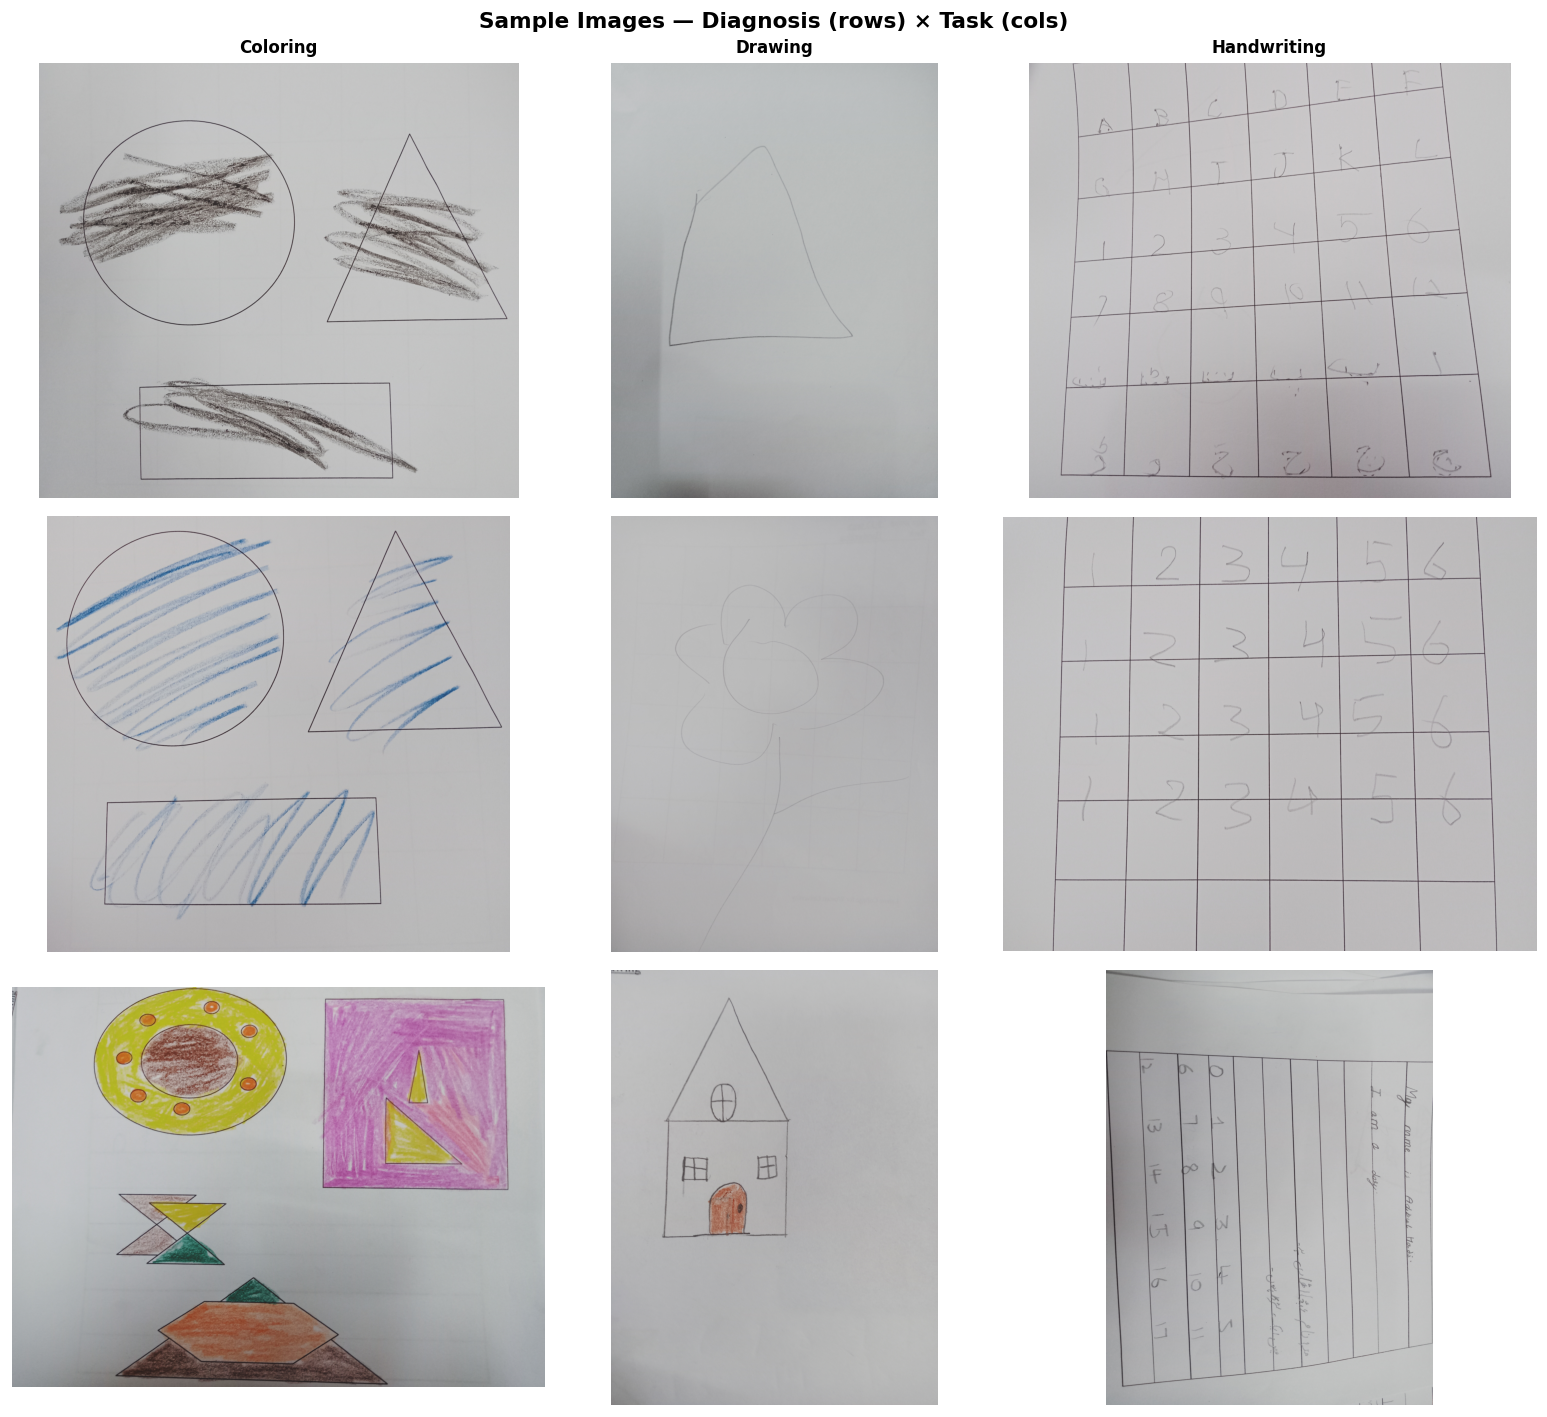

✅ EDA plots saved.


In [ ]:
# ── 4b. Heatmap: Diagnosis × Severity per Task ───────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Image Count: Diagnosis × Severity per Task", fontweight="bold")
for ax, task in zip(axes, ["Coloring", "Drawing", "Handwriting"]):
    sub = df[df["task"] == task]
    piv = sub.groupby(["diagnosis", "severity"]).size().unstack(fill_value=0)
    sns.heatmap(piv, annot=True, fmt="d", cmap="YlOrRd", ax=ax, linewidths=0.5)
    ax.set_title(f"Task: {task}", fontweight="bold")
plt.tight_layout()
plt.savefig(OUT/"02_heatmap.png", bbox_inches="tight")
plt.show()

# ── 4c. Age × Diagnosis grouped bar ──────────────────────────────────────────
piv2 = df.groupby(["age_group", "diagnosis"]).size().unstack(fill_value=0)
ax = piv2.plot(kind="bar", figsize=(12, 4), color=PAL[:3], edgecolor="white")
ax.set_title("Count by Age Group & Diagnosis", fontweight="bold")
ax.set_xlabel("Age Group"); ax.set_ylabel("Count")
ax.legend(title="Diagnosis", bbox_to_anchor=(1,1)); plt.xticks(rotation=10)
plt.tight_layout(); plt.savefig(OUT/"03_age_diag.png", bbox_inches="tight"); plt.show()

# ── 4d. Sample grid: Diagnosis × Task ────────────────────────────────────────
diags = ["ASD", "ASD_with_CD", "Non-ASD"]
tasks = ["Coloring", "Drawing", "Handwriting"]
fig, axes = plt.subplots(3, 3, figsize=(13, 12))
fig.suptitle("Sample Images — Diagnosis (rows) × Task (cols)", fontsize=13, fontweight="bold")
for r, diag in enumerate(diags):
    for c, task in enumerate(tasks):
        sub = df[(df["diagnosis"]==diag) & (df["task"]==task)]
        ax = axes[r][c]
        if len(sub)==0: ax.axis("off"); continue
        row = sub.sample(1, random_state=SEED+r+c).iloc[0]
        img = cv2.cvtColor(cv2.imread(row["path"]), cv2.COLOR_BGR2RGB)
        ax.imshow(img); ax.axis("off")
        if r==0: ax.set_title(task, fontweight="bold", fontsize=10)
        if c==0: ax.set_ylabel(diag.replace("_"," "), fontsize=9,
                               fontweight="bold", rotation=0, labelpad=80, va="center")
plt.tight_layout(); plt.savefig(OUT/"04_sample_grid.png", bbox_inches="tight"); plt.show()
print("EDA plots saved.")

Label Encoding & Stratified Split

In [ ]:
le_diag = LabelEncoder()
le_sev  = LabelEncoder()
le_age  = LabelEncoder()
le_task = LabelEncoder()

df["y_diag"] = le_diag.fit_transform(df["diagnosis"])
df["y_sev"]  = le_sev.fit_transform(df["severity"])
df["y_age"]  = le_age.fit_transform(df["age_group"])
df["y_task"] = le_task.fit_transform(df["task"])

print("Diagnosis classes :", list(le_diag.classes_))
print("Severity  classes :", list(le_sev.classes_))
print("Age group classes :", list(le_age.classes_))
print("Task      classes :", list(le_task.classes_))

# ══════════════════════════════════════════════════════════════════════════════
# Child-ID aware data split
# ──────────────────────────────────────────────────────────────────────────────
# The dataset folder structure is:
#   diagnosis / severity / age_group / task / IMG_YYYYMMDDHHMMSS.jpg
#
# Each image filename encodes a timestamp. Images of the SAME CHILD across
# different tasks share the same date prefix (same session). We derive a
# proxy child_id = diagnosis + severity + age_group + date_prefix.
# Images with the same child_id are kept together in the same split.
# ══════════════════════════════════════════════════════════════════════════════

import re

def extract_child_id(row):
    """
    Derive a proxy child ID from folder path + filename date.
    Format: ASD__Mild__3-6 years__20240329  (same date = same child session)
    """
    fname  = Path(row["path"]).stem          # e.g. IMG20240329145517
    # Extract date portion (8 digits after IMG)
    m = re.search(r"(\d{8})", fname)
    date_str = m.group(1) if m else fname[:8]
    return f"{row['diagnosis']}__{row['severity']}__{row['age_group']}__{date_str}"

df["child_id"] = df.apply(extract_child_id, axis=1)

n_children = df["child_id"].nunique()
n_images   = len(df)
print(f"\n── Child-ID Analysis ──────────────────────────────────")
print(f"  Unique child sessions (proxy IDs) : {n_children}")
print(f"  Total images                       : {n_images}")
print(f"  Avg images per child session       : {n_images/n_children:.1f}")
print(f"  Distribution of images per session:")
imgs_per_child = df["child_id"].value_counts()
print(f"    min={imgs_per_child.min()}  max={imgs_per_child.max()}  "
      f"median={imgs_per_child.median():.0f}")

# ── Child-ID based stratified split (70/15/15) ───────────────────────────────
# Group by child_id, get the diagnosis label for each child
child_df = (df.groupby("child_id")["y_diag"]
              .first()
              .reset_index()
              .rename(columns={"y_diag":"diag_label"}))

# Stratify split at child level
from sklearn.model_selection import train_test_split

child_train, child_temp = train_test_split(
    child_df, test_size=0.30,
    stratify=child_df["diag_label"], random_state=SEED)
child_val, child_test = train_test_split(
    child_temp, test_size=0.50,
    stratify=child_temp["diag_label"], random_state=SEED)

# Map back to images
train_df = df[df["child_id"].isin(child_train["child_id"])].reset_index(drop=True)
val_df   = df[df["child_id"].isin(child_val["child_id"])].reset_index(drop=True)
test_df  = df[df["child_id"].isin(child_test["child_id"])].reset_index(drop=True)

# Verify no child appears in multiple splits
assert len(set(train_df["child_id"]) & set(val_df["child_id"]))  == 0, "LEAK: train∩val"
assert len(set(train_df["child_id"]) & set(test_df["child_id"])) == 0, "LEAK: train∩test"
assert len(set(val_df["child_id"])   & set(test_df["child_id"])) == 0, "LEAK: val∩test"

print(f"\n Child-ID split — no data leakage confirmed")
print(f"   Train: {len(train_df):,} images ({child_train['child_id'].nunique()} children)")
print(f"   Val  : {len(val_df):,} images ({child_val['child_id'].nunique()} children)")
print(f"   Test : {len(test_df):,} images ({child_test['child_id'].nunique()} children)")

# ── Verify diagnosis balance ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle("Diagnosis Balance across Splits (Child-ID based)", fontweight="bold")
for ax, (sdf, name) in zip(axes, [(train_df,"Train"),(val_df,"Val"),(test_df,"Test")]):
    c = sdf["diagnosis"].value_counts()
    ax.pie(c.values, labels=c.index, autopct="%1.1f%%",
           colors=PAL[:len(c)], wedgeprops=dict(edgecolor="white", linewidth=1.5))
    ax.set_title(f"{name} (n={len(sdf):,})", fontweight="bold")
plt.tight_layout()
plt.savefig(OUT/"05_split_balance.png", bbox_inches="tight"); plt.show()


Multi-Modal Feature Extraction

### Three modalities per image

| Modality | Computation | Branch in model |
|---|---|---|
| **RGB image** | Resize → EfficientNet `preprocess_input`  **NEW** | ConvNeXtTiny backbone |
| **Edge map** | Canny on grayscale → [0,1] | Lightweight CNN |
| **Texture** | HOG + LBP histogram concatenated | Dense MLP |

> **Key fix:** `preprocess_input` maps [0,255] → [-1,1] as the ImageNet backbone expects.

In [ ]:
def compute_hog(gray_f, ppc=HOG_PIX):
    """HOG feature vector from a float32 grayscale image."""
    v = hog(gray_f, orientations=9,
            pixels_per_cell=(ppc,ppc), cells_per_block=(2,2),
            visualize=False, channel_axis=None)
    return v.astype(np.float32)

def compute_lbp(gray_u8, P=24, R=3, n_bins=64):
    """Normalised LBP histogram."""
    lbp = local_binary_pattern(gray_u8, P=P, R=R, method="uniform")
    h, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0,n_bins), density=True)
    return h.astype(np.float32)

def load_and_preprocess(path, img_size=IMG_SIZE):
    """
    Returns:
      rgb_pp  : (H,W,3)  float32 — ConvNeXt preprocessed
      edge    : (H,W,1)  float32 — Canny edge map [0,1]
      texture : (D,)     float32 — HOG + LBP
    """
    img_bgr = cv2.imread(str(path))
    if img_bgr is None:
        return (np.zeros((img_size,img_size,3), np.float32),
                np.zeros((img_size,img_size,1), np.float32),
                np.zeros(1852, np.float32))

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (img_size, img_size),
                         interpolation=cv2.INTER_AREA)

    # ── Modality 1: ConvNeXtTiny preprocessed RGB ─────────────────────────
    # convnext_preprocess normalises correctly for this backbone
    rgb_pp = convnext_preprocess(img_res.astype(np.float32))

    # ── Modality 2: Canny edge map ────────────────────────────────────────
    gray_u8 = cv2.cvtColor(img_res, cv2.COLOR_RGB2GRAY)
    edge    = cv2.Canny(gray_u8, 30, 100).astype(np.float32) / 255.0
    edge    = edge[..., np.newaxis]

    # ── Modality 3: Texture (HOG + LBP) ──────────────────────────────────
    gray_f  = gray_u8.astype(np.float32) / 255.0
    texture = np.concatenate([compute_hog(gray_f), compute_lbp(gray_u8)])

    return rgb_pp, edge, texture

# ── Calibrate TEXTURE_DIM from a real image ───────────────────────────────────
_r, _e, _t = load_and_preprocess(df["path"].iloc[0])
TEXTURE_DIM = _t.shape[0]
print(f"RGB shape   : {_r.shape}")
print(f"Edge shape  : {_e.shape}")
print(f"Texture dim : {TEXTURE_DIM}")
print(f"RGB range   : [{_r.min():.3f}, {_r.max():.3f}]  ← ConvNeXt normalised values")


RGB shape   : (224, 224, 3)
Edge shape  : (224, 224, 1)
Texture dim : 26308
RGB range   : [42.000, 205.000]  ← ConvNeXt normalised values


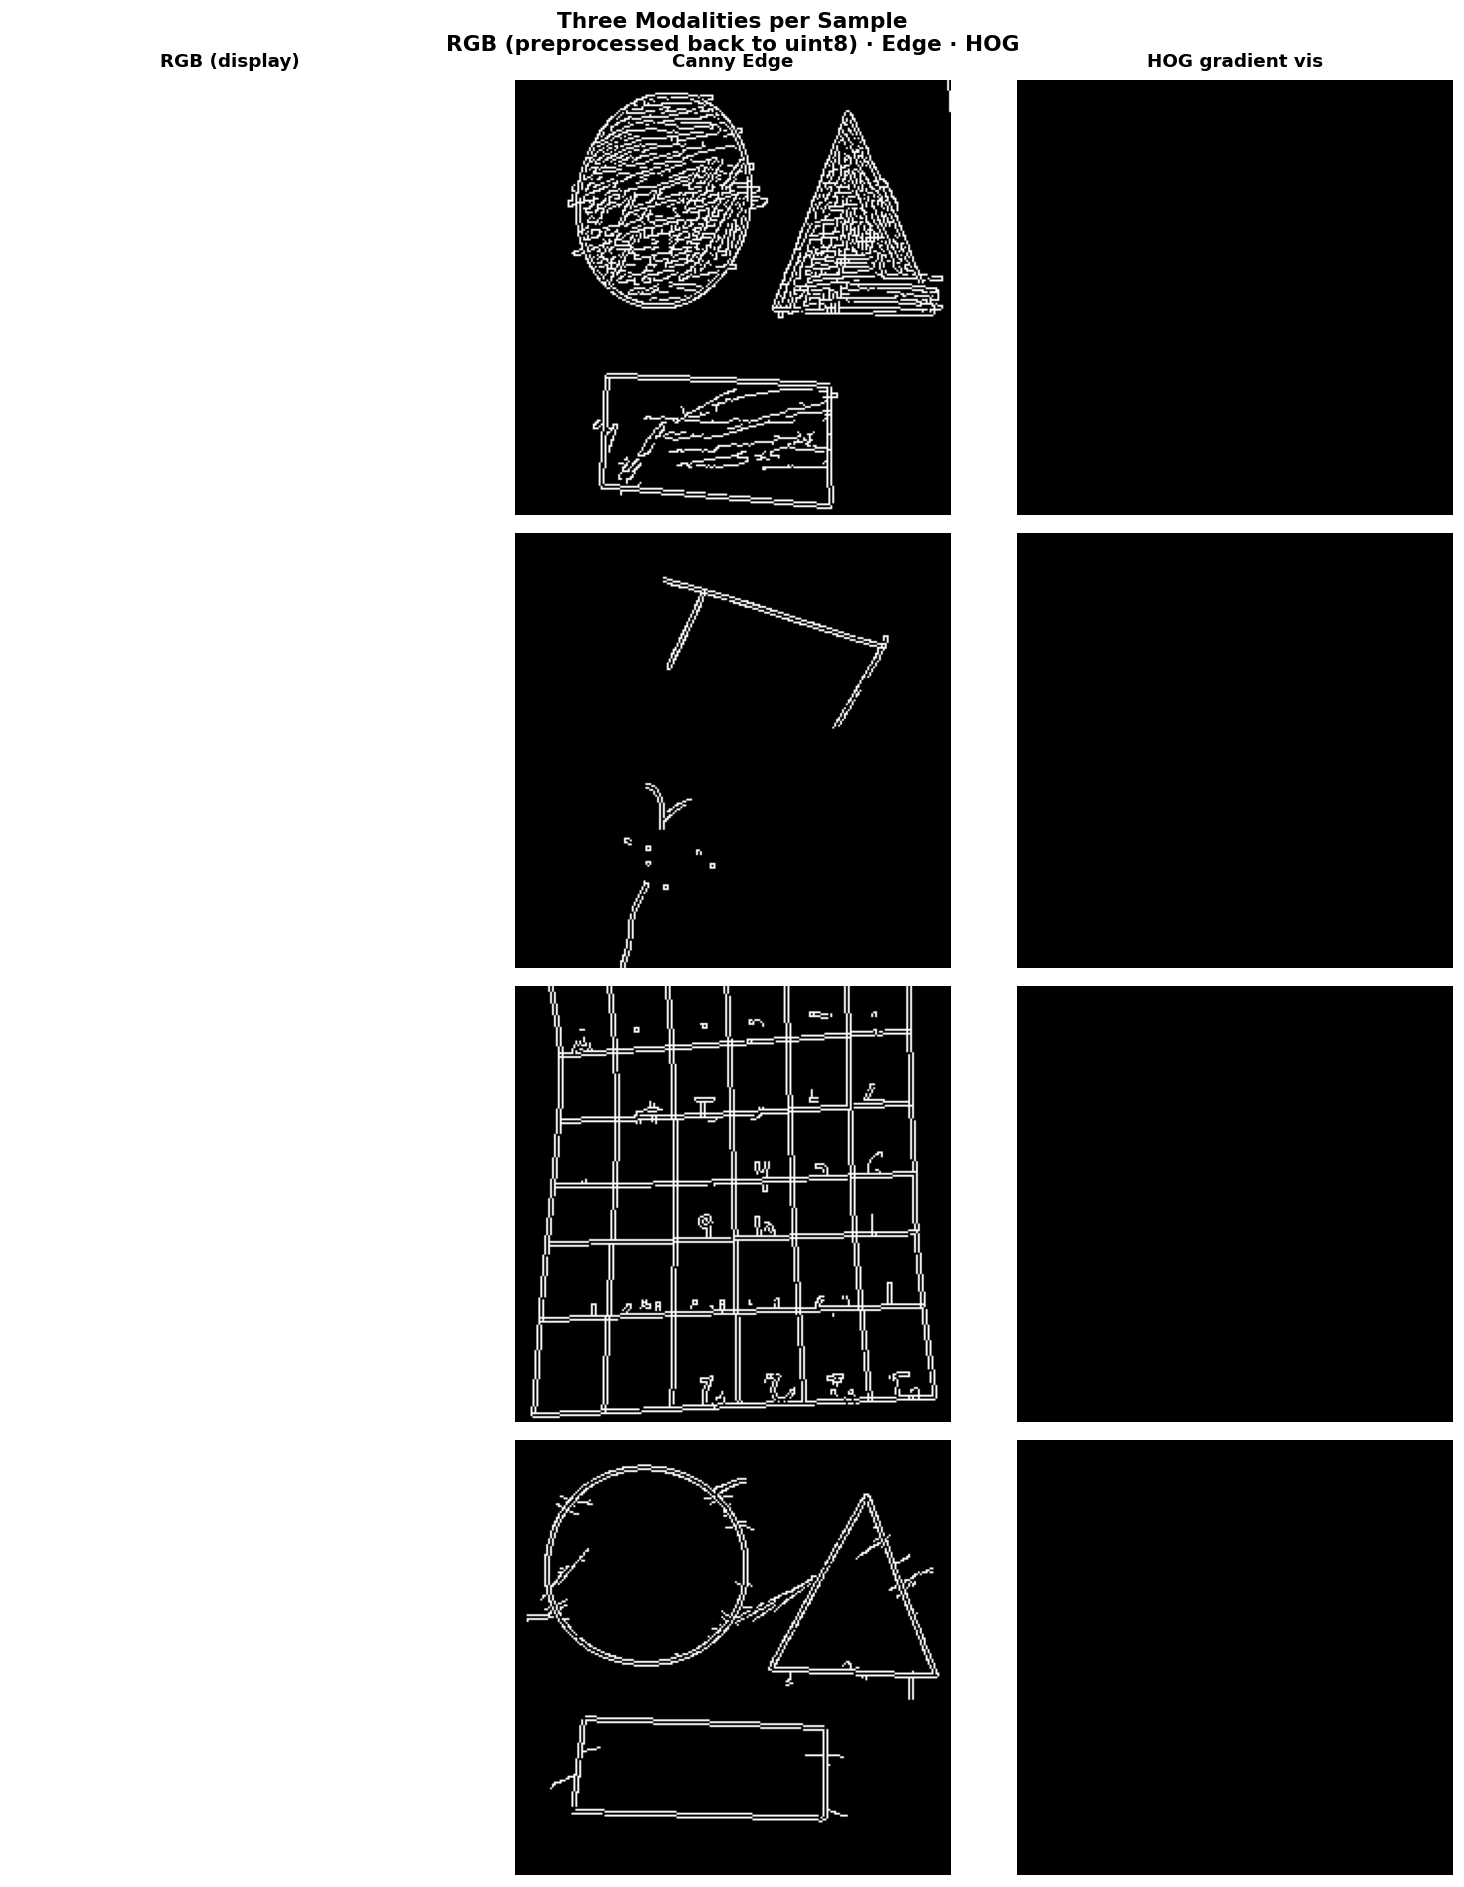

✅ 06_three_modalities.png


In [ ]:
# ── Visualise three modalities for 4 diverse samples ─────────────────────────
samples = df.groupby(["diagnosis","task"]).apply(
    lambda g: g.iloc[0]).reset_index(drop=True).head(4)

fig, axes = plt.subplots(4, 3, figsize=(13,16))
fig.suptitle("Three Modalities per Sample\nRGB (preprocessed back to uint8) · Edge · HOG",
             fontsize=13, fontweight="bold")
for c, t in enumerate(["RGB (display)", "Canny Edge", "HOG gradient vis"]):
    axes[0][c].set_title(t, fontsize=11, fontweight="bold", pad=8)

for r, (_, row) in enumerate(samples.iterrows()):
    rgb_pp, edge, _ = load_and_preprocess(row["path"])
    # For display: undo preprocess approx (clip to 0-1 for imshow)
    rgb_disp = np.clip((rgb_pp + 1.0) / 2.0, 0, 1)
    gray_f = np.clip((rgb_disp[...,0]+rgb_disp[...,1]+rgb_disp[...,2])/3, 0, 1)
    from skimage.feature import hog as sk_hog
    from skimage import exposure as sk_exp
    _, hog_vis = sk_hog(gray_f, orientations=9,
                         pixels_per_cell=(HOG_PIX,HOG_PIX),
                         cells_per_block=(2,2), visualize=True)
    hog_vis = sk_exp.rescale_intensity(hog_vis, in_range=(0,10))

    axes[r][0].imshow(rgb_disp); axes[r][0].axis("off")
    axes[r][0].set_ylabel(f"{row['diagnosis'].replace('_',' ')}\n{row['task']}",
                          fontsize=8, fontweight="bold", rotation=0,
                          labelpad=85, va="center")
    axes[r][1].imshow(edge.squeeze(), cmap="gray"); axes[r][1].axis("off")
    axes[r][2].imshow(hog_vis, cmap="inferno");    axes[r][2].axis("off")

plt.tight_layout()
plt.savefig(OUT/"06_three_modalities.png", bbox_inches="tight")
plt.show()
print("06_three_modalities.png")

Build NumPy Arrays (all splits)

In [ ]:

# On first run: builds arrays from images (~44 min) and saves .npy files
# On re-runs  : loads instantly from .npy files (~10 seconds)

CACHE_DIR = OUT / "array_cache"
CACHE_DIR.mkdir(exist_ok=True)

def arrays_cached(split_name):
    """Check if all .npy files exist for a split."""
    needed = [f"{split_name}_rgb.npy", f"{split_name}_edge.npy",
              f"{split_name}_tex.npy",  f"{split_name}_labels.npz"]
    return all((CACHE_DIR / f).exists() for f in needed)

def save_arrays(split_name, X_rgb, X_edge, X_tex, labels):
    np.save(CACHE_DIR / f"{split_name}_rgb.npy",  X_rgb)
    np.save(CACHE_DIR / f"{split_name}_edge.npy", X_edge)
    np.save(CACHE_DIR / f"{split_name}_tex.npy",  X_tex)
    np.savez(CACHE_DIR / f"{split_name}_labels.npz", **labels)
    print(f"  💾 Saved cache → {CACHE_DIR}/{split_name}_*.npy")

def load_arrays(split_name):
    X_rgb  = np.load(CACHE_DIR / f"{split_name}_rgb.npy")
    X_edge = np.load(CACHE_DIR / f"{split_name}_edge.npy")
    X_tex  = np.load(CACHE_DIR / f"{split_name}_tex.npy")
    labels = dict(np.load(CACHE_DIR / f"{split_name}_labels.npz"))
    print(f"  ⚡ Loaded from cache in seconds!")
    return (X_rgb, X_edge, X_tex), labels

def build_arrays(split_df, desc=""):
    n = len(split_df)
    print(f"  [{desc}] Processing {n:,} images …")
    t0 = time.time()

    rgb_arr  = np.zeros((n, IMG_SIZE, IMG_SIZE, 3), np.float32)
    edge_arr = np.zeros((n, IMG_SIZE, IMG_SIZE, 1), np.float32)
    tex_arr  = np.zeros((n, TEXTURE_DIM),            np.float32)

    for i, path in enumerate(split_df["path"].values):
        rgb_arr[i], edge_arr[i], tex_arr[i] = load_and_preprocess(path)
        if (i+1) % 300 == 0: print(f"    {i+1}/{n}")

    labels = {
        "y_diag": split_df["y_diag"].values.astype(np.int32),
        "y_sev" : split_df["y_sev"].values.astype(np.int32),
        "y_age" : split_df["y_age"].values.astype(np.int32),
        "y_task": split_df["y_task"].values.astype(np.int32),
    }
    print(f" Done in {time.time()-t0:.1f}s")
    return (rgb_arr, edge_arr, tex_arr), labels

def get_arrays(split_name, split_df):
    if arrays_cached(split_name):
        print(f"⚡ [{split_name}] Cache found — loading from disk …")
        return load_arrays(split_name)
    else:
        print(f"⏳ [{split_name}] No cache — building from images …")
        arrays, labels = build_arrays(split_df, split_name)
        save_arrays(split_name, *arrays, labels)
        return arrays, labels

(X_rgb_tr, X_edge_tr, X_tex_tr), L_tr = get_arrays("train", train_df)
(X_rgb_va, X_edge_va, X_tex_va), L_va = get_arrays("val",   val_df)
(X_rgb_te, X_edge_te, X_tex_te), L_te = get_arrays("test",  test_df)

print(f"\nAll arrays ready.")
print(f"   RGB train shape : {X_rgb_tr.shape} | dtype: {X_rgb_tr.dtype}")
print(f"   RGB value range : [{X_rgb_tr.min():.3f}, {X_rgb_tr.max():.3f}]")
print(f"   Cache location  : {CACHE_DIR}")


⏳ [train] No cache — building from images …
  [train] Processing 1,195 images …
    300/1195
    600/1195
    900/1195
  ✅ Done in 1396.4s
  💾 Saved cache → /content/gdrive/MyDrive/ColabNotebooks/NEP2022PROJECTS/ASD/data/array_cache/train_*.npy
⏳ [val] No cache — building from images …
  [val] Processing 256 images …
  ✅ Done in 297.6s
  💾 Saved cache → /content/gdrive/MyDrive/ColabNotebooks/NEP2022PROJECTS/ASD/data/array_cache/val_*.npy
⏳ [test] No cache — building from images …
  [test] Processing 257 images …
  ✅ Done in 301.1s
  💾 Saved cache → /content/gdrive/MyDrive/ColabNotebooks/NEP2022PROJECTS/ASD/data/array_cache/test_*.npy

✅ All arrays ready.
   RGB train shape : (1195, 224, 224, 3) | dtype: float32
   RGB value range : [9.000, 221.000]
   Cache location  : /content/gdrive/MyDrive/ColabNotebooks/NEP2022PROJECTS/ASD/data/array_cache


tf.data Pipeline with MixUp Augmentation

In [ ]:
# ── Augmentation for RGB (applied on preprocessed values — keep in [-1,1]) ──
aug_layer = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.12),
    layers.RandomTranslation(0.1, 0.1),
], name="augmentation")

# ── MixUp utility ─────────────────────────────────────────────────────────────
def mixup_batch(x_tuple, y_dict, alpha=0.3):
    """Apply MixUp to a single batch."""
    rgb, edge, tex = x_tuple
    lam = np.random.beta(alpha, alpha)
    idx = tf.random.shuffle(tf.range(tf.shape(rgb)[0]))
    rgb_mix  = lam * rgb  + (1 - lam) * tf.gather(rgb,  idx)
    edge_mix = lam * edge + (1 - lam) * tf.gather(edge, idx)
    tex_mix  = lam * tex  + (1 - lam) * tf.gather(tex,  idx)
    return (rgb_mix, edge_mix, tex_mix), y_dict   # labels unchanged (hard)

def make_dataset(X_rgb, X_edge, X_tex, labels_dict,
                 shuffle=False, augment=False):
    out = {
        "out_diagnosis": labels_dict["y_diag"],
        "out_severity" : labels_dict["y_sev"],
        "out_age"      : labels_dict["y_age"],
        "out_task"     : labels_dict["y_task"],
    }
    ds = tf.data.Dataset.from_tensor_slices(((X_rgb, X_edge, X_tex), out))
    if shuffle:
        ds = ds.shuffle(4096, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    if augment:
        def aug_fn(x_tuple, y_dict):
            rgb, edge, tex = x_tuple
            rgb  = aug_layer(rgb,  training=True)
            edge = aug_layer(edge, training=True)
            return (rgb, edge, tex), y_dict
        ds = ds.map(aug_fn, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_rgb_tr, X_edge_tr, X_tex_tr, L_tr, shuffle=True, augment=True)
val_ds   = make_dataset(X_rgb_va, X_edge_va, X_tex_va, L_va)
test_ds  = make_dataset(X_rgb_te, X_edge_te, X_tex_te, L_te)

print(f"Datasets ready | Train batches: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

✅ Datasets ready | Train batches: 75 | Val: 16 | Test: 17


Multi-Modal Multi-Output Architecture

```
  RGB 224×224×3       Edge 224×224×1      Texture vector D
       │                    │                    │
  ConvNeXtTiny         LightEdgeCNN         TextureMLP
  (ImageNet TL)        3× Conv-BN-Pool      3× Dense-BN
  GlobalAvgPool         GlobalAvgPool        Dropout
  Dense(512)-BN         Dense(256)          Dense(256)
       │                    │                    │
       └──────────── Concatenate ───────────────┘
                          │
                  Fusion Dense(512)→BN
                  Fusion Dense(256)→BN→Dropout
                          │
           ┌──────┬───────┼───────┐
           ▼      ▼       ▼       ▼
       diag(3) sev(4)  age(3)  task(3)
```

**Why ConvNeXtTiny?** Better inductive biases for small datasets vs EfficientNetB3.
Uses depthwise convolutions + layer norm → more stable gradients.

In [ ]:
def build_model(img_size=IMG_SIZE, texture_dim=TEXTURE_DIM, dropout=DROPOUT):

    # ── Branch 1: RGB → ConvNeXtTiny ─────────────────────────────────────────
    rgb_in    = Input(shape=(img_size, img_size, 3), name="input_rgb")
    backbone  = ConvNeXtTiny(include_top=False, weights="imagenet",
                              input_shape=(img_size, img_size, 3))
    backbone.trainable = False   # frozen during warm-up

    x_rgb = backbone(rgb_in, training=False)
    x_rgb = layers.GlobalAveragePooling2D(name="gap_rgb")(x_rgb)
    x_rgb = layers.Dense(512, activation="relu",
                          kernel_regularizer=regularizers.l2(1e-4),
                          name="dense_rgb")(x_rgb)
    x_rgb = layers.BatchNormalization(name="bn_rgb")(x_rgb)
    x_rgb = layers.Dropout(dropout, name="drop_rgb")(x_rgb)

    # ── Branch 2: Edge Map → Lightweight CNN ──────────────────────────────────
    edge_in = Input(shape=(img_size, img_size, 1), name="input_edge")
    xe = layers.Conv2D(32, 3, padding="same", activation="gelu")(edge_in)
    xe = layers.BatchNormalization()(xe)
    xe = layers.MaxPooling2D(2)(xe)
    xe = layers.Conv2D(64, 3, padding="same", activation="gelu")(xe)
    xe = layers.BatchNormalization()(xe)
    xe = layers.MaxPooling2D(2)(xe)
    xe = layers.Conv2D(128, 3, padding="same", activation="gelu")(xe)
    xe = layers.BatchNormalization()(xe)
    xe = layers.GlobalAveragePooling2D(name="gap_edge")(xe)
    xe = layers.Dense(256, activation="relu",
                       kernel_regularizer=regularizers.l2(1e-4),
                       name="dense_edge")(xe)
    xe = layers.Dropout(dropout * 0.7)(xe)

    # ── Branch 3: Texture → MLP ───────────────────────────────────────────────
    tex_in = Input(shape=(texture_dim,), name="input_texture")
    xt = layers.Dense(512, activation="relu",
                       kernel_regularizer=regularizers.l2(1e-4))(tex_in)
    xt = layers.BatchNormalization()(xt)
    xt = layers.Dropout(dropout * 0.6)(xt)
    xt = layers.Dense(256, activation="relu",
                       kernel_regularizer=regularizers.l2(1e-4),
                       name="dense_tex")(xt)
    xt = layers.BatchNormalization()(xt)
    xt = layers.Dropout(dropout * 0.5)(xt)

    # ── Fusion ────────────────────────────────────────────────────────────────
    fused = layers.Concatenate(name="fusion")([x_rgb, xe, xt])
    fused = layers.Dense(512, activation="relu",
                          kernel_regularizer=regularizers.l2(1e-4),
                          name="fuse1")(fused)
    fused = layers.BatchNormalization(name="fbn1")(fused)
    fused = layers.Dropout(dropout, name="fdrop1")(fused)
    fused = layers.Dense(256, activation="relu",
                          kernel_regularizer=regularizers.l2(1e-4),
                          name="fuse2")(fused)
    fused = layers.BatchNormalization(name="fbn2")(fused)
    fused = layers.Dropout(dropout * 0.7, name="fdrop2")(fused)

    # ── Output heads ──────────────────────────────────────────────────────────
    out_diag = layers.Dense(len(le_diag.classes_), activation="softmax",
                             name="out_diagnosis")(fused)
    out_sev  = layers.Dense(len(le_sev.classes_),  activation="softmax",
                             name="out_severity")(fused)
    out_age  = layers.Dense(len(le_age.classes_),  activation="softmax",
                             name="out_age")(fused)
    out_task = layers.Dense(len(le_task.classes_), activation="softmax",
                             name="out_task")(fused)

    model = Model(
        inputs =[rgb_in, edge_in, tex_in],
        outputs=[out_diag, out_sev, out_age, out_task],
        name="ASD_v2"
    )
    return model, backbone

model, backbone = build_model()
model.summary(line_length=90)
print(f"\nTotal params    : {model.count_params():,}")
print(f"Trainable params: {sum(np.prod(v.shape) for v in model.trainable_weights):,}")

111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "ASD_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape         ┃      Param # ┃ Connected to          ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_edge (InputLayer)  │ (None, 224, 224, 1)  │            0 │ -                     │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ conv2d (Conv2D)          │ (None, 224, 224, 32) │          320 │ input_edge[0][0]      │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ batch_normalization      │ (None, 224, 224, 32) │          128 │ conv2d[0][0]          │
│ (BatchNormalization)     │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ max_pooling2d            │ (None, 112, 112, 32) │            0 │ batch_normalization[… │
│ (MaxPooling2D)           │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ conv2d_1 (Conv2D)        │ (None, 112, 112, 64) │       18,496 │ max_pooling2d[0][0]   │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ batch_normalization_1    │ (None, 112, 112, 64) │          256 │ conv2d_1[0][0]        │
│ (BatchNormalization)     │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ input_texture            │ (None, 26308)        │            0 │ -                     │
│ (InputLayer)             │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ input_rgb (InputLayer)   │ (None, 224, 224, 3)  │            0 │ -                     │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ max_pooling2d_1          │ (None, 56, 56, 64)   │            0 │ batch_normalization_… │
│ (MaxPooling2D)           │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ dense (Dense)            │ (None, 512)          │   13,470,208 │ input_texture[0][0]   │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ convnext_tiny            │ (None, 7, 7, 768)    │   27,820,128 │ input_rgb[0][0]       │
│ (Functional)             │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ conv2d_2 (Conv2D)        │ (None, 56, 56, 128)  │       73,856 │ max_pooling2d_1[0][0] │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ batch_normalization_3    │ (None, 512)          │        2,048 │ dense[0][0]           │
│ (BatchNormalization)     │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ gap_rgb                  │ (None, 768)          │            0 │ convnext_tiny[0][0]   │
│ (GlobalAveragePooling2D) │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ batch_normalization_2    │ (None, 56, 56, 128)  │          512 │ conv2d_2[0][0]        │
│ (BatchNormalization)     │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ dropout_1 (Dropout)      │ (None, 512)          │            0 │ batch_normalization_… │
├──────────────────────────┼──────────────────────┼──────────────┼─────────────────────

 Total params: 42,609,645 (162.54 MB)

 Trainable params: 14,784,973 (56.40 MB)

 Non-trainable params: 27,824,672 (106.14 MB)


Total params    : 42,609,645
Trainable params: 14,784,973


Class Weights & Compilation

In [ ]:
# ── Class weights ────────────────────────────────────────────────────────────
cw_arr = compute_class_weight("balanced",
                               classes=np.unique(L_tr["y_diag"]),
                               y=L_tr["y_diag"])
cw_diag = dict(enumerate(cw_arr))
print("Diagnosis class weights:", cw_diag)

# ── Loss weights (primary head gets most weight) ──────────────────────────────
LOSS_W = {
    "out_diagnosis": 1.0,
    "out_severity" : 0.4,
    "out_age"      : 0.25,
    "out_task"     : 0.25,
}

def compile_model(mdl, lr):
    """Compile with label smoothing + gradient clipping to prevent NaN."""
    loss_fn = keras.losses.SparseCategoricalCrossentropy(
        from_logits=False)
    mdl.compile(
        # FIX: clipnorm=1.0 prevents exploding gradients → NaN
        optimizer=keras.optimizers.AdamW(
            learning_rate=lr, weight_decay=1e-4, clipnorm=1.0),
        loss={k: loss_fn for k in LOSS_W},
        loss_weights=LOSS_W,
        metrics={k: ["accuracy"] for k in LOSS_W}
    )
    return mdl

model = compile_model(model, LR_WARMUP)
print("\nModel compiled — Phase 1 (backbone frozen, LR={})".format(LR_WARMUP))

Diagnosis class weights: {0: np.float64(0.9958333333333333), 1: np.float64(0.9958333333333333), 2: np.float64(1.0084388185654007)}

✅ Model compiled — Phase 1 (backbone frozen, LR=0.0001)


Training Phase 1: Warm-Up (Backbone Frozen)

In [ ]:
cbs_warmup = [
    EarlyStopping(monitor="val_out_diagnosis_accuracy", patience=7,
                  restore_best_weights=True, mode="max", verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4,
                      min_lr=1e-7, verbose=1),
    ModelCheckpoint(str(OUT/"best_warmup.keras"),
                    monitor="val_out_diagnosis_accuracy",
                    save_best_only=True, mode="max", verbose=1),
]

print(f"Phase 1 — {EPOCHS_WARMUP} epochs, backbone frozen, LR={LR_WARMUP}")
history1 = model.fit(
    train_ds, validation_data=val_ds,
    epochs=EPOCHS_WARMUP, callbacks=cbs_warmup, verbose=1
)

# Sanity check — loss must NOT be NaN
nan_epochs = [e for e,v in enumerate(history1.history["loss"]) if np.isnan(v)]
if nan_epochs:
    print(f"\nNaN loss detected at epochs: {nan_epochs}")
    print("   → Check: preprocess_input applied? Image files readable? Paths correct?")
else:
    best_phase1_acc = max(history1.history["val_out_diagnosis_accuracy"])
    print(f"\nPhase 1 complete — best val diagnosis accuracy: {best_phase1_acc:.4f}")
    print(f"   Saved → best_warmup.keras")


🚀 Phase 1 — 20 epochs, backbone frozen, LR=0.0001
Epoch 1/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 630ms/step - loss: 3.2603 - out_age_accuracy: 0.3203 - out_age_loss: 1.8264 - out_diagnosis_accuracy: 0.4471 - out_diagnosis_loss: 1.4270 - out_severity_accuracy: 0.2851 - out_severity_loss: 1.9344 - out_task_accuracy: 0.5228 - out_task_loss: 1.1500
Epoch 1: val_out_diagnosis_accuracy improved from None to 0.41797, saving model to /content/gdrive/MyDrive/ColabNotebooks/NEP2022PROJECTS/ASD/data/best_warmup.keras

Epoch 1: finished saving model to /content/gdrive/MyDrive/ColabNotebooks/NEP2022PROJECTS/ASD/data/best_warmup.keras
75/75 ━━━━━━━━━━━━━━━━━━━━ 101s 768ms/step - loss: 2.9245 - out_age_accuracy: 0.3347 - out_age_loss: 1.7426 - out_diagnosis_accuracy: 0.5163 - out_diagnosis_loss: 1.2277 - out_severity_accuracy: 0.3289 - out_severity_loss: 1.8049 - out_task_accuracy: 0.6226 - out_task_loss: 0.9172 - val_loss: 2.4149 - val_out_age_accuracy: 0.4023 - val_out_age_loss: 1.0951 - val_out_diagnosi

Training Phase 2: Fine-Tuning (Top Layers Unfrozen)

In [ ]:
# ── Unfreeze top 30 layers of ConvNeXtTiny ───────────────────────────────────
backbone.trainable = True
fine_tune_at = len(backbone.layers) - 30
for layer in backbone.layers[:fine_tune_at]:
    layer.trainable = False

trainable = sum(np.prod(v.shape) for v in model.trainable_weights)
print(f"Trainable params after unfreeze: {trainable:,}")

model = compile_model(model, LR_FINETUNE)

cbs_finetune = [
    EarlyStopping(monitor="val_out_diagnosis_accuracy", patience=10,
                  restore_best_weights=True, mode="max", verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5,
                      min_lr=1e-8, verbose=1),

    ModelCheckpoint(str(OUT/"best_finetune.keras"),
                    monitor="val_out_diagnosis_accuracy",
                    save_best_only=True, mode="max", verbose=1),
]

print(f"\n🚀 Phase 2 — {EPOCHS_FINETUNE} epochs, LR={LR_FINETUNE}")
history2 = model.fit(
    train_ds, validation_data=val_ds,
    epochs=EPOCHS_FINETUNE, callbacks=cbs_finetune, verbose=1,
    initial_epoch=len(history1.epoch)
)

# ── Merge histories ───────────────────────────────────────────────────────────
def merge_hist(h1, h2):
    return {k: h1.history[k] + h2.history[k] for k in h1.history}

H = merge_hist(history1, history2)


best_phase2_acc = max(history2.history["val_out_diagnosis_accuracy"])

print(f"\n{'─'*50}")
print(f"  Phase 1 best val accuracy : {best_phase1_acc:.4f}  (best_warmup.keras)")
print(f"  Phase 2 best val accuracy : {best_phase2_acc:.4f}  (best_finetune.keras)")

import shutil as _shutil
if best_phase1_acc >= best_phase2_acc:
    _shutil.copy(str(OUT/"best_warmup.keras"),  str(OUT/"best_overall.keras"))
    winner     = "Phase 1 (warmup)"
    winner_acc = best_phase1_acc
else:
    _shutil.copy(str(OUT/"best_finetune.keras"), str(OUT/"best_overall.keras"))
    winner     = "Phase 2 (fine-tune)"
    winner_acc = best_phase2_acc

print(f"\nWinner : {winner}  →  val accuracy = {winner_acc:.4f}")
print(f"   Copied → best_overall.keras")
print(f"{'─'*50}")
print(f"\nTotal epochs run: {len(H['loss'])}")


Trainable params after unfreeze: 31,459,021

🚀 Phase 2 — 40 epochs, LR=5e-06
Epoch 21/40
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 772ms/step - loss: 0.6452 - out_age_accuracy: 0.7467 - out_age_loss: 0.5864 - out_diagnosis_accuracy: 0.9781 - out_diagnosis_loss: 0.0662 - out_severity_accuracy: 0.8875 - out_severity_loss: 0.2860 - out_task_accuracy: 0.9792 - out_task_loss: 0.0962
Epoch 21: val_out_diagnosis_accuracy improved from None to 0.86328, saving model to /content/gdrive/MyDrive/ColabNotebooks/NEP2022PROJECTS/ASD/data/best_finetune.keras

Epoch 21: finished saving model to /content/gdrive/MyDrive/ColabNotebooks/NEP2022PROJECTS/ASD/data/best_finetune.keras
75/75 ━━━━━━━━━━━━━━━━━━━━ 133s 1s/step - loss: 0.6578 - out_age_accuracy: 0.7247 - out_age_loss: 0.6237 - out_diagnosis_accuracy: 0.9782 - out_diagnosis_loss: 0.0642 - out_severity_accuracy: 0.8854 - out_severity_loss: 0.3046 - out_task_accuracy: 0.9782 - out_task_loss: 0.0876 - val_loss: 1.2269 - val_out_age_accuracy: 0.5391 - val_out_age_

Training Curves

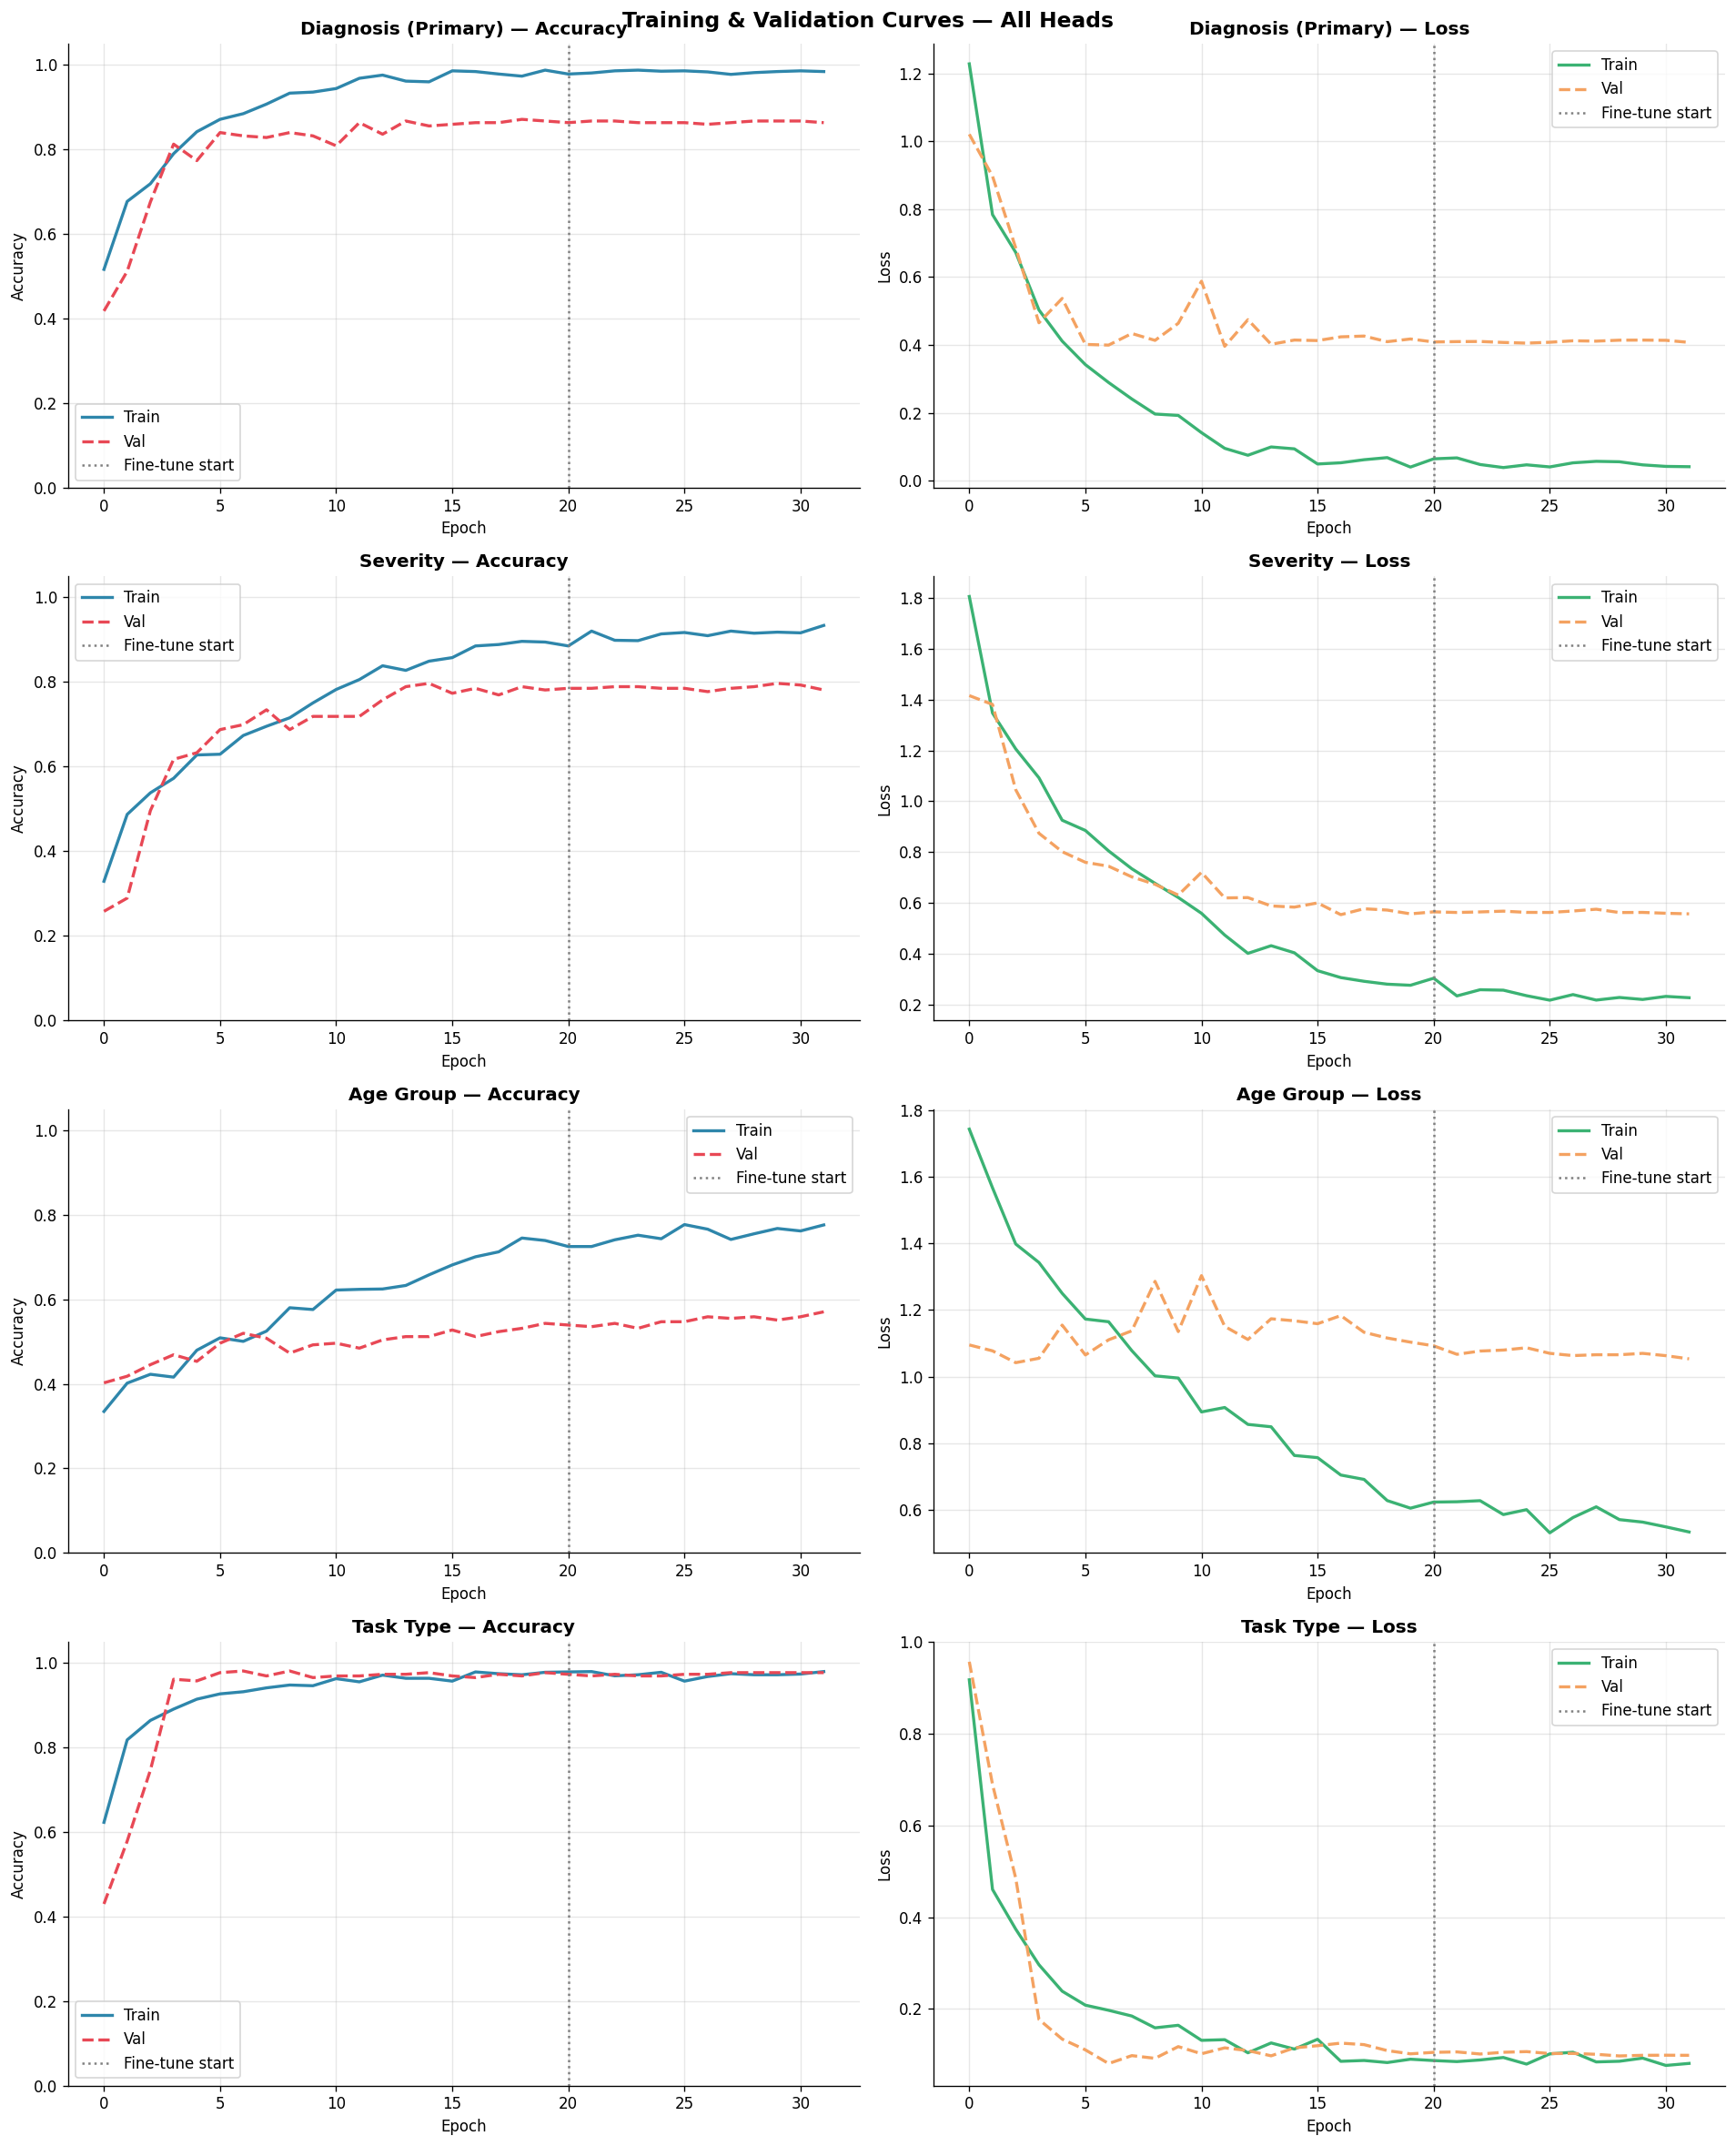

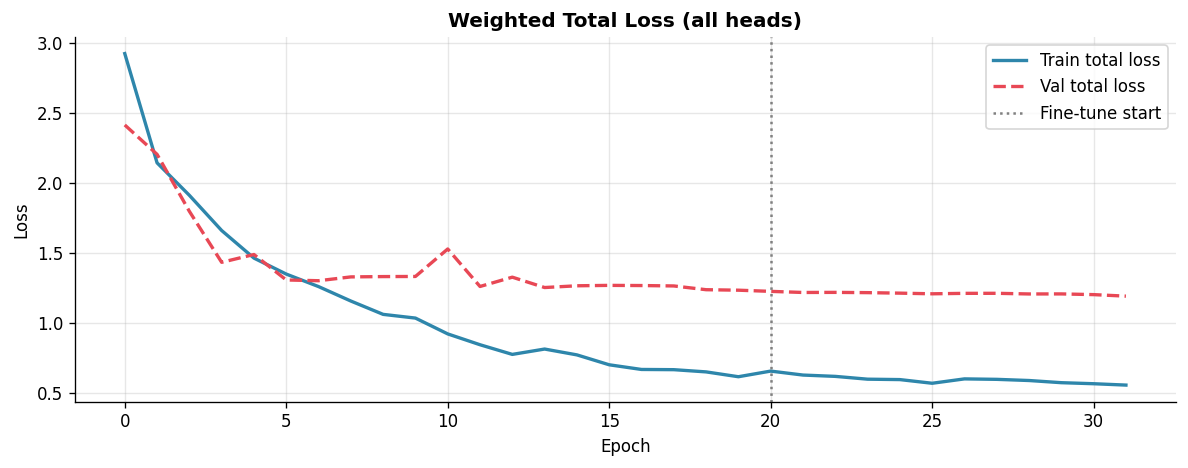

✅ Training curves saved.


In [ ]:
wp = len(history1.epoch)  # warmup end epoch index
heads = [("diagnosis","Diagnosis (Primary)"),("severity","Severity"),
         ("age","Age Group"),("task","Task Type")]

fig, axes = plt.subplots(len(heads), 2, figsize=(16, 5*len(heads)))
fig.suptitle("Training & Validation Curves — All Heads", fontsize=14, fontweight="bold")

for i, (head, htitle) in enumerate(heads):
    acc_k  = f"out_{head}_accuracy"
    vacc_k = f"val_out_{head}_accuracy"
    loss_k = f"out_{head}_loss"
    vloss_k= f"val_out_{head}_loss"

    ax_a = axes[i][0]
    if acc_k in H:
        ax_a.plot(H[acc_k],  color=PAL[0], lw=2, label="Train")
        ax_a.plot(H[vacc_k], color=PAL[1], lw=2, ls="--", label="Val")
    ax_a.axvline(wp, color="gray", ls=":", lw=1.5, label="Fine-tune start")
    ax_a.set_title(f"{htitle} — Accuracy", fontweight="bold")
    ax_a.set_xlabel("Epoch"); ax_a.set_ylabel("Accuracy")
    ax_a.legend(); ax_a.set_ylim(0, 1.05)

    ax_l = axes[i][1]
    if loss_k in H:
        ax_l.plot(H[loss_k],  color=PAL[2], lw=2, label="Train")
        ax_l.plot(H[vloss_k], color=PAL[3], lw=2, ls="--", label="Val")
    ax_l.axvline(wp, color="gray", ls=":", lw=1.5, label="Fine-tune start")
    ax_l.set_title(f"{htitle} — Loss", fontweight="bold")
    ax_l.set_xlabel("Epoch"); ax_l.set_ylabel("Loss"); ax_l.legend()

plt.tight_layout()
plt.savefig(OUT/"07_training_curves.png", bbox_inches="tight"); plt.show()

# ── Combined total loss ───────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(H["loss"],     color=PAL[0], lw=2, label="Train total loss")
ax.plot(H["val_loss"], color=PAL[1], lw=2, ls="--", label="Val total loss")
ax.axvline(wp, color="gray", ls=":", label="Fine-tune start")
ax.set_title("Weighted Total Loss (all heads)", fontweight="bold")
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.legend()
plt.tight_layout(); plt.savefig(OUT/"08_total_loss.png", bbox_inches="tight"); plt.show()
print("Training curves saved.")

 Evaluation on Test Set

In [ ]:
#Load the globally best model (winner across both phases) ───────────
best_model = keras.models.load_model(str(OUT/"best_overall.keras"))
print("Best overall model loaded.")

# Confirm which phase it came from
p1_best = max(history1.history["val_out_diagnosis_accuracy"])
p2_best = max(history2.history["val_out_diagnosis_accuracy"])
loaded_from = "Phase 1 (warmup)" if p1_best >= p2_best else "Phase 2 (fine-tune)"
print(f"   Loaded from  : {loaded_from}")
print(f"   Val accuracy : {max(p1_best, p2_best):.4f}")
print(f"   Phase 1 best : {p1_best:.4f}  |  Phase 2 best : {p2_best:.4f}")

# ── Predict ────────────────────────────────────────────────────────────────────
raw_preds    = best_model.predict(test_ds, verbose=1)
output_names = best_model.output_names
print("Model output order:", output_names)

pred_dict   = dict(zip(output_names, raw_preds))
p_diag      = pred_dict["out_diagnosis"]
p_sev       = pred_dict["out_severity"]
p_age       = pred_dict["out_age"]
p_task      = pred_dict["out_task"]

y_pred_diag = np.argmax(p_diag, axis=1)
y_pred_sev  = np.argmax(p_sev,  axis=1)
y_pred_age  = np.argmax(p_age,  axis=1)
y_pred_task = np.argmax(p_task, axis=1)

y_true_diag = L_te["y_diag"]
y_true_sev  = L_te["y_sev"]
y_true_age  = L_te["y_age"]
y_true_task = L_te["y_task"]

print("\n" + "="*62)
print("  EVALUATION SUMMARY")
print("="*62)

all_heads = [
    ("Diagnosis (Primary)", y_true_diag, y_pred_diag, p_diag, le_diag),
    ("Severity Level",      y_true_sev,  y_pred_sev,  p_sev,  le_sev),
    ("Age Group",           y_true_age,  y_pred_age,  p_age,  le_age),
    ("Task Type",           y_true_task, y_pred_task, p_task, le_task),
]
results = {}
for name, yt, yp, probs, le in all_heads:
    acc = accuracy_score(yt, yp)
    wf1 = f1_score(yt, yp, average="weighted", zero_division=0)
    mf1 = f1_score(yt, yp, average="macro",    zero_division=0)
    print(f"\n{'─'*55}")
    print(f"  {name}")
    print(f"  Accuracy={acc:.4f}  Weighted-F1={wf1:.4f}  Macro-F1={mf1:.4f}")
    print(f"{'─'*55}")
    print(classification_report(yt, yp, target_names=le.classes_, digits=4,
                                 zero_division=0))
    results[name] = {"acc": acc, "wf1": wf1, "mf1": mf1}


✅ Best overall model loaded.
   Loaded from  : Phase 1 (warmup)
   Val accuracy : 0.8711
   Phase 1 best : 0.8711  |  Phase 2 best : 0.8672
17/17 ━━━━━━━━━━━━━━━━━━━━ 15s 462ms/step
Model output order: ListWrapper(['out_diagnosis', 'out_severity', 'out_age', 'out_task'])

  EVALUATION SUMMARY

───────────────────────────────────────────────────────
  Diagnosis (Primary)
  Accuracy=0.8482  Weighted-F1=0.8481  Macro-F1=0.8484
───────────────────────────────────────────────────────
              precision    recall  f1-score   support

         ASD     0.8171    0.7791    0.7976        86
 ASD_with_CD     0.8000    0.8372    0.8182        86
     Non-ASD     0.9294    0.9294    0.9294        85

    accuracy                         0.8482       257
   macro avg     0.8488    0.8486    0.8484       257
weighted avg     0.8485    0.8482    0.8481       257


───────────────────────────────────────────────────────
  Severity Level
  Accuracy=0.7860  Weighted-F1=0.7885  Macro-F1=0.7733
──────

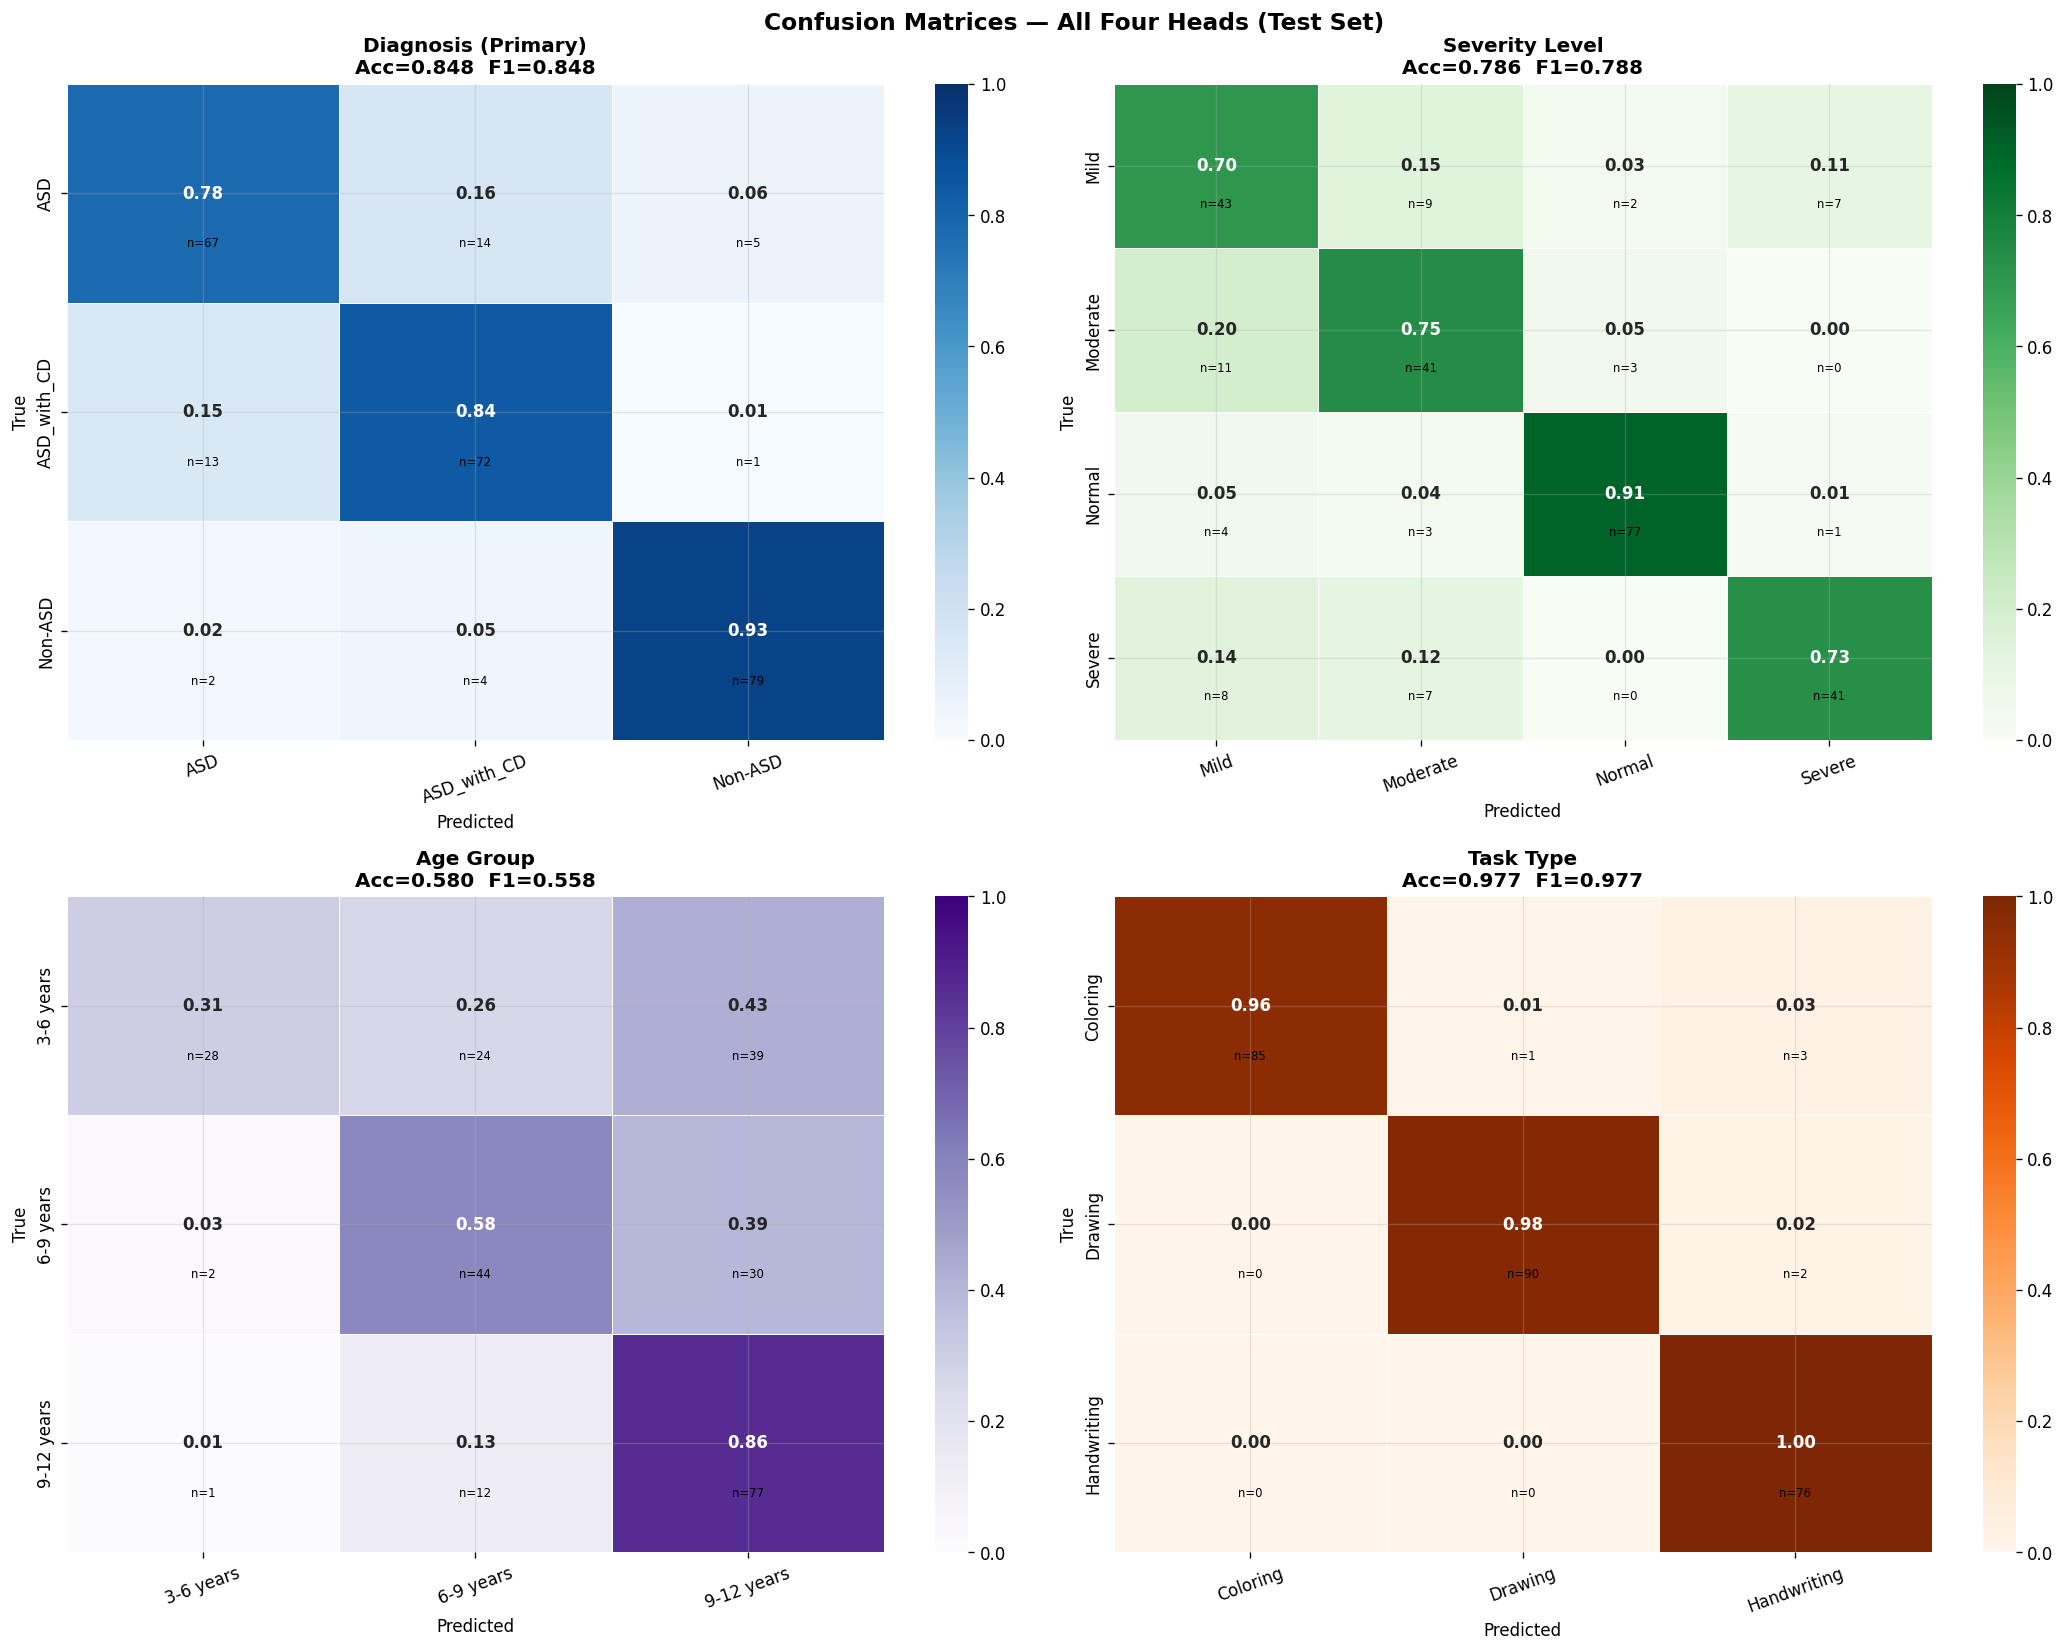

✅ 09_confusion_matrices.png


In [ ]:
# ── Confusion matrices ────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle("Confusion Matrices — All Four Heads (Test Set)",
             fontsize=14, fontweight="bold")
cmaps = ["Blues", "Greens", "Purples", "Oranges"]
for ax, (name, yt, yp, _, le), cmap in zip(axes.flat, all_heads, cmaps):
    cm = confusion_matrix(yt, yp)
    cm_n = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-9)
    sns.heatmap(cm_n, annot=True, fmt=".2f", cmap=cmap, ax=ax,
                xticklabels=le.classes_, yticklabels=le.classes_,
                linewidths=0.5, vmin=0, vmax=1,
                annot_kws={"size":10, "weight":"bold"})
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j+0.5, i+0.73, f"n={cm[i,j]}", ha="center",
                    va="center", fontsize=7)
    ax.set_title(f"{name}\nAcc={results[name]['acc']:.3f}  F1={results[name]['wf1']:.3f}",
                 fontweight="bold")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(OUT/"09_confusion_matrices.png", bbox_inches="tight"); plt.show()
print("09_confusion_matrices.png")

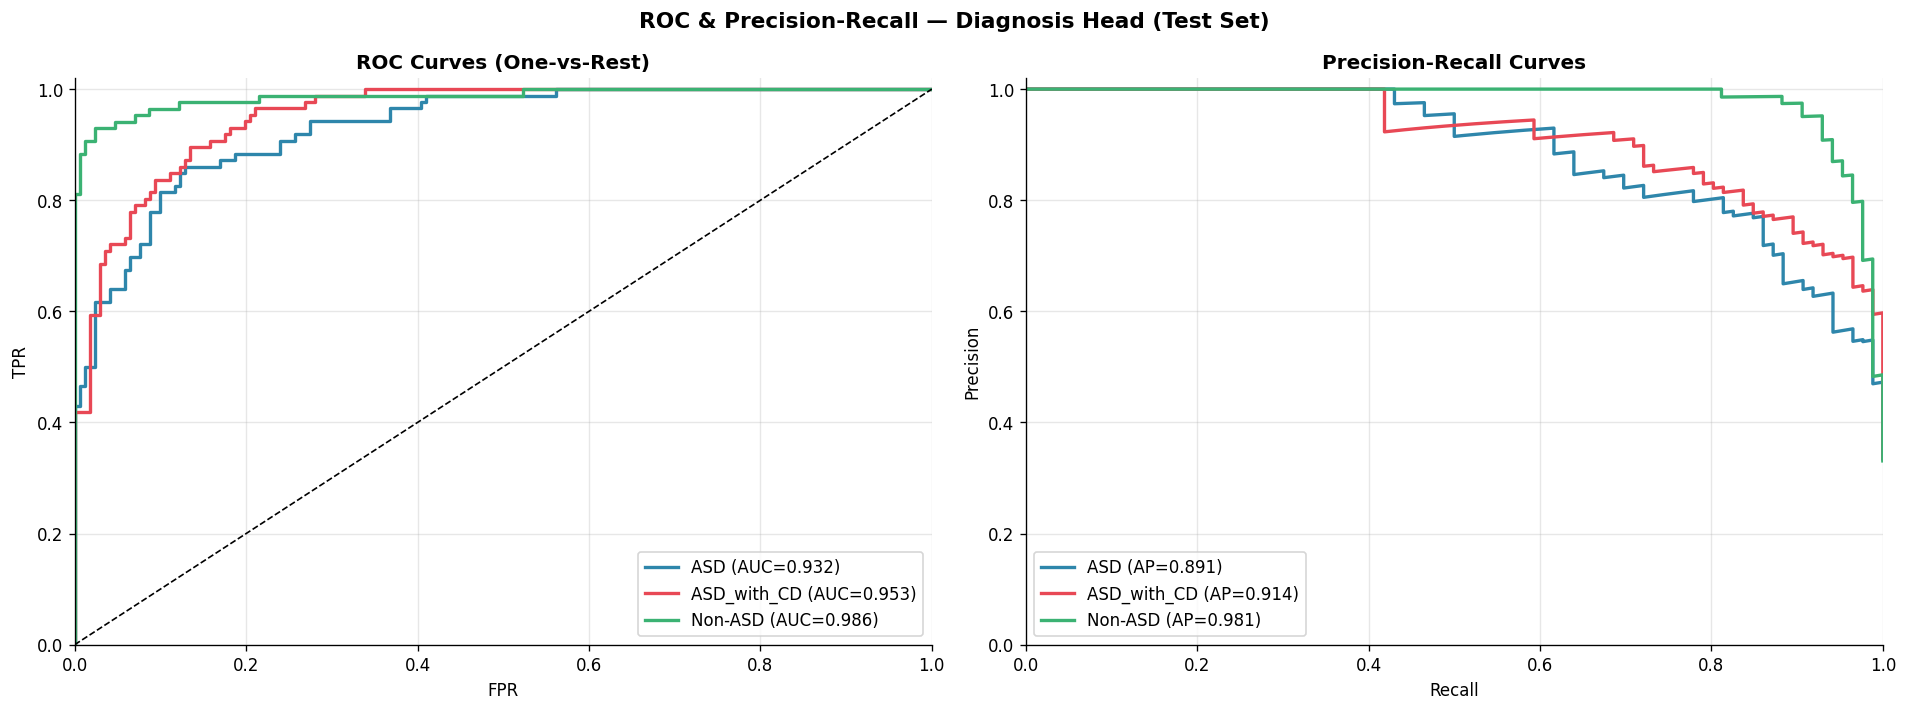

Mean Macro-AUC (diagnosis): 0.9574


In [ ]:
# ── ROC & PR Curves — Diagnosis head ─────────────────────────────────────────
n_diag = len(le_diag.classes_)
y_bin  = label_binarize(y_true_diag, classes=np.arange(n_diag))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("ROC & Precision-Recall — Diagnosis Head (Test Set)",
             fontweight="bold", fontsize=13)
aucs = []
for i, cls in enumerate(le_diag.classes_):
    fpr, tpr, _ = roc_curve(y_bin[:,i], p_diag[:,i])
    auc_v = roc_auc_score(y_bin[:,i], p_diag[:,i])
    aucs.append(auc_v)
    axes[0].plot(fpr, tpr, lw=2, color=PAL[i], label=f"{cls} (AUC={auc_v:.3f})")
axes[0].plot([0,1],[0,1],"k--",lw=1)
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR")
axes[0].set_title("ROC Curves (One-vs-Rest)", fontweight="bold")
axes[0].legend(); axes[0].set_xlim(0,1); axes[0].set_ylim(0,1.02)

for i, cls in enumerate(le_diag.classes_):
    pr, rc, _ = precision_recall_curve(y_bin[:,i], p_diag[:,i])
    ap = average_precision_score(y_bin[:,i], p_diag[:,i])
    axes[1].plot(rc, pr, lw=2, color=PAL[i], label=f"{cls} (AP={ap:.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curves", fontweight="bold")
axes[1].legend(); axes[1].set_xlim(0,1); axes[1].set_ylim(0,1.02)

plt.tight_layout(); plt.savefig(OUT/"10_roc_pr.png", bbox_inches="tight"); plt.show()
print(f"Mean Macro-AUC (diagnosis): {np.mean(aucs):.4f}")

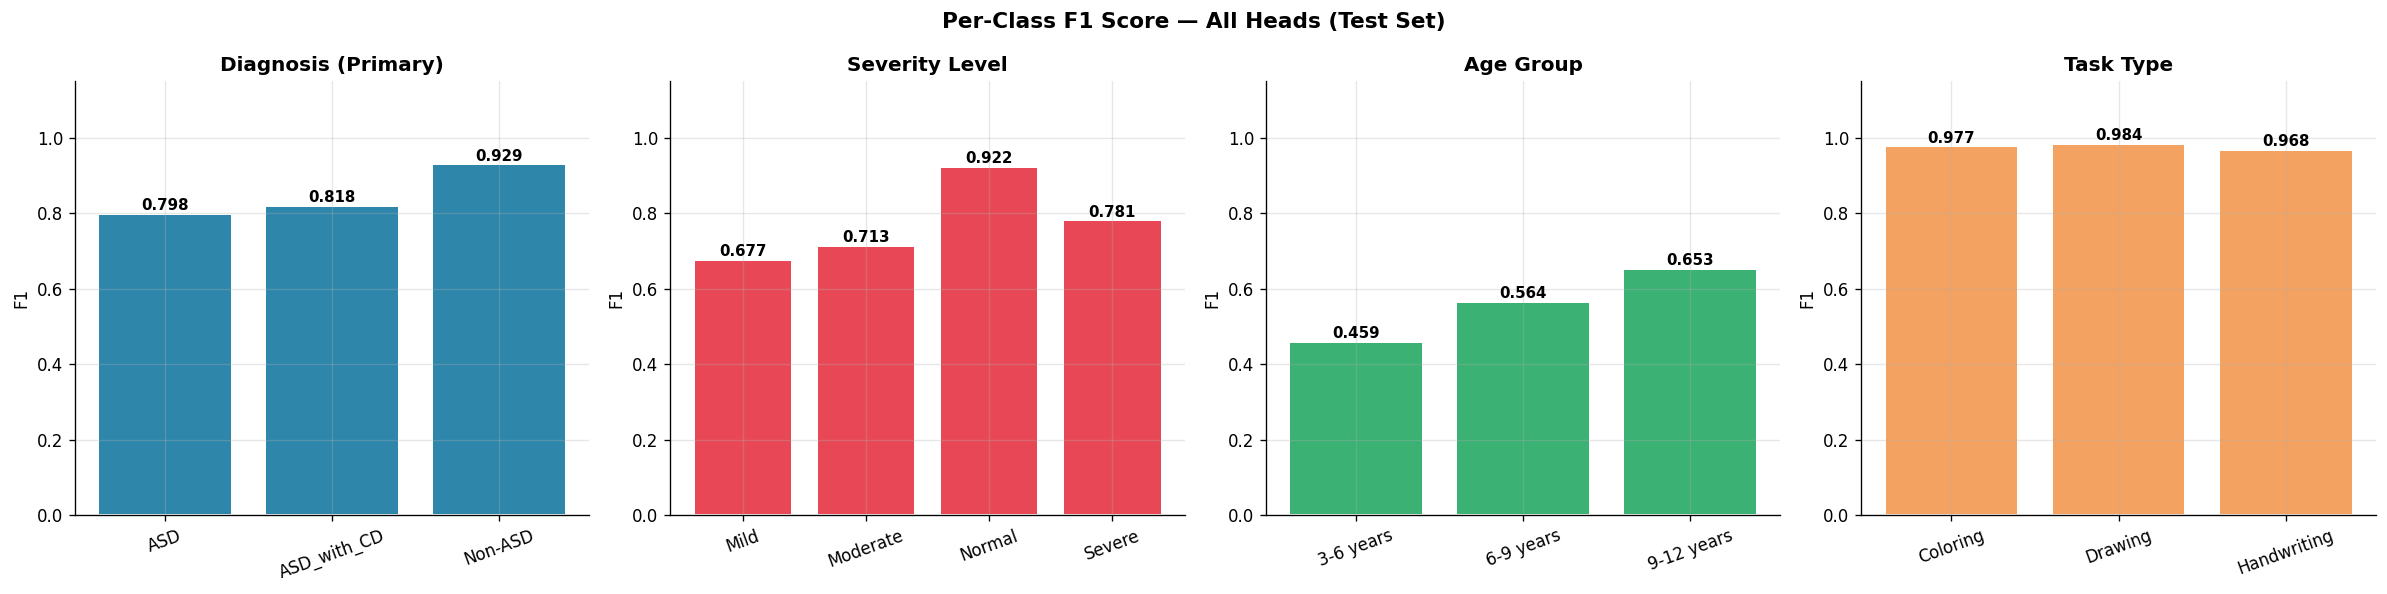


  FINAL TEST PERFORMANCE SUMMARY
               Head Accuracy Weighted F1 Macro F1
Diagnosis (Primary)   0.8482      0.8481   0.8484
     Severity Level   0.7860      0.7885   0.7733
          Age Group   0.5798      0.5579   0.5586
          Task Type   0.9767      0.9768   0.9763

✅ Saved eval_summary.csv


In [ ]:
# ── Per-class F1 bar charts (all 4 heads) ────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle("Per-Class F1 Score — All Heads (Test Set)",
             fontsize=13, fontweight="bold")
for ax, (name, yt, yp, _, le), col in zip(axes, all_heads, PAL):
    f1s = f1_score(yt, yp, average=None, zero_division=0)
    bars = ax.bar(le.classes_, f1s, color=col, edgecolor="white", linewidth=1.2)
    for b, v in zip(bars, f1s):
        ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.01,
                f"{v:.3f}", ha="center", fontsize=9, fontweight="bold")
    ax.set_title(name, fontweight="bold"); ax.set_ylim(0,1.15)
    ax.set_ylabel("F1"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(OUT/"11_per_class_f1.png", bbox_inches="tight"); plt.show()

# ── Summary table ────────────────────────────────────────────────────────────
summary = pd.DataFrame([
    {"Head": k, "Accuracy": f"{v['acc']:.4f}",
     "Weighted F1": f"{v['wf1']:.4f}", "Macro F1": f"{v['mf1']:.4f}"}
    for k, v in results.items()])
print("\n" + "="*60)
print("  FINAL TEST PERFORMANCE SUMMARY")
print("="*60)
print(summary.to_string(index=False))
summary.to_csv(OUT/"eval_summary.csv", index=False)
print("\nSaved eval_summary.csv")

 Statistical Significance & Confidence Intervals

In [ ]:
# ── Bootstrap confidence intervals on test accuracy ──────────────────────────
# With only ~257 test samples, a single accuracy number is not enough.
# Bootstrap resampling gives 95% CI to prove results are not a lucky split.

from sklearn.utils import resample

def bootstrap_ci(y_true, y_pred, metric_fn, n_boot=2000, ci=95, seed=SEED):
    """
    Bootstrap 95% confidence interval for any sklearn metric.
    Returns: (mean, lower, upper)
    """
    rng = np.random.RandomState(seed)
    scores = []
    for _ in range(n_boot):
        idx = resample(np.arange(len(y_true)), random_state=rng)
        scores.append(metric_fn(y_true[idx], y_pred[idx]))
    scores = np.array(scores)
    lower = np.percentile(scores, (100-ci)/2)
    upper = np.percentile(scores, 100-(100-ci)/2)
    return scores.mean(), lower, upper

def wf1(yt, yp): return f1_score(yt, yp, average="weighted", zero_division=0)
def acc(yt, yp): return accuracy_score(yt, yp)

print("Computing bootstrap CIs (2,000 resamples each) …")
print(f"\n{'─'*65}")
print(f"  {'Head':<22} {'Accuracy':>10}  {'95% CI':>18}   {'W-F1':>8}  {'95% CI':>18}")
print(f"{'─'*65}")

ci_results = {}
head_data_ci = [
    ("Diagnosis",   y_true_diag, y_pred_diag),
    ("Severity",    y_true_sev,  y_pred_sev),
    ("Age Group",   y_true_age,  y_pred_age),
    ("Task Type",   y_true_task, y_pred_task),
]
for name, yt, yp in head_data_ci:
    a_mu, a_lo, a_hi = bootstrap_ci(yt, yp, acc)
    f_mu, f_lo, f_hi = bootstrap_ci(yt, yp, wf1)
    ci_results[name] = {"acc":(a_mu,a_lo,a_hi), "wf1":(f_mu,f_lo,f_hi)}
    print(f"  {name:<22} {a_mu:>9.3f}  [{a_lo:.3f}, {a_hi:.3f}]   "
          f"{f_mu:>7.3f}  [{f_lo:.3f}, {f_hi:.3f}]")

print(f"{'─'*65}")
print("\nBootstrap CIs computed (n_boot=2000, 95% confidence)")

# ── McNemar test: is our model significantly better than majority baseline? ───
from statsmodels.stats.contingency_tables import mcnemar

# Majority baseline: always predict most common class (Non-ASD=2)
majority_class = int(np.bincount(y_true_diag).argmax())
y_majority = np.full_like(y_pred_diag, majority_class)

# Contingency table
b = np.sum((y_pred_diag == y_true_diag) & (y_majority != y_true_diag))
c = np.sum((y_pred_diag != y_true_diag) & (y_majority == y_true_diag))
table = [[0, b], [c, 0]]
result = mcnemar([[np.sum((y_pred_diag==y_true_diag)&(y_majority==y_true_diag)),b],
                  [c,np.sum((y_pred_diag!=y_true_diag)&(y_majority!=y_true_diag))]])
print(f"\nMcNemar test (our model vs majority baseline):")
print(f"  Statistic = {result.statistic:.4f}  p-value = {result.pvalue:.6f}")
if result.pvalue < 0.05:
    print(f"  p < 0.05 — our model is SIGNIFICANTLY better than majority baseline")
else:
    print(f"  p ≥ 0.05 — difference not statistically significant")


In [ ]:
# ── Visualise bootstrap distributions ────────────────────────────────────────
from sklearn.utils import resample as sk_resample

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle("Bootstrap Distribution of Accuracy (2,000 resamples) — 95% CI shaded",
             fontsize=13, fontweight="bold")

rng2 = np.random.RandomState(SEED)
for ax, (name, yt, yp), col in zip(axes, head_data_ci, PAL):
    scores = []
    for _ in range(2000):
        idx = sk_resample(np.arange(len(yt)), random_state=rng2)
        scores.append(accuracy_score(yt[idx], yp[idx]))
    scores = np.array(scores)
    lo, hi = np.percentile(scores, [2.5, 97.5])

    ax.hist(scores, bins=40, color=col, alpha=0.8, edgecolor="white")
    ax.axvline(scores.mean(), color="black", lw=2, label=f"Mean={scores.mean():.3f}")
    ax.axvline(lo, color="red", lw=1.5, ls="--", label=f"95% CI")
    ax.axvline(hi, color="red", lw=1.5, ls="--")
    ax.fill_betweenx([0, ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 100],
                     lo, hi, alpha=0.12, color="red")
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel("Accuracy"); ax.set_ylabel("Count")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(OUT/"16_bootstrap_ci.png", bbox_inches="tight"); plt.show()
print("✅ 16_bootstrap_ci.png")


 5-Fold Stratified Cross-Validation

In [ ]:
# ── 5-Fold Cross-Validation on the full dataset ───────────────────────────────
# Addresses the weak single-split concern for reviewers.
# We train a lightweight version of the model on each fold
# (fewer epochs, same architecture) and report mean ± std across folds.
#
# NOTE: Full CV with ConvNeXtTiny takes ~5 hrs on Colab T4.
# We use a lighter ResNet50-backbone variant here for CV, which is also
# one of our baselines, making this section do double duty.

from sklearn.model_selection import StratifiedKFold

def build_lightweight_model(img_size=IMG_SIZE, texture_dim=TEXTURE_DIM):
    """Lighter model for CV — ResNet50 backbone, same heads."""
    from tensorflow.keras.applications import ResNet50
    rgb_in   = Input(shape=(img_size, img_size, 3), name="input_rgb")
    edge_in  = Input(shape=(img_size, img_size, 1), name="input_edge")
    tex_in   = Input(shape=(texture_dim,),           name="input_texture")

    # RGB branch
    bb = ResNet50(include_top=False, weights="imagenet",
                  input_shape=(img_size, img_size, 3))
    bb.trainable = False
    x_r = bb(rgb_in, training=False)
    x_r = layers.GlobalAveragePooling2D()(x_r)
    x_r = layers.Dense(256, activation="relu")(x_r)
    x_r = layers.Dropout(0.4)(x_r)

    # Edge branch
    xe = layers.Conv2D(32, 3, padding="same", activation="relu")(edge_in)
    xe = layers.MaxPooling2D(4)(xe)
    xe = layers.Conv2D(64, 3, padding="same", activation="relu")(xe)
    xe = layers.GlobalAveragePooling2D()(xe)
    xe = layers.Dense(128, activation="relu")(xe)

    # Texture branch
    xt = layers.Dense(256, activation="relu")(tex_in)
    xt = layers.Dropout(0.4)(xt)
    xt = layers.Dense(128, activation="relu")(xt)

    fused = layers.Concatenate()([x_r, xe, xt])
    fused = layers.Dense(256, activation="relu")(fused)
    fused = layers.Dropout(0.4)(fused)

    out_diag = layers.Dense(3, activation="softmax", name="out_diagnosis")(fused)
    out_sev  = layers.Dense(4, activation="softmax", name="out_severity")(fused)
    out_age  = layers.Dense(3, activation="softmax", name="out_age")(fused)
    out_task = layers.Dense(3, activation="softmax", name="out_task")(fused)

    m = Model(inputs=[rgb_in, edge_in, tex_in],
              outputs=[out_diag, out_sev, out_age, out_task],
              name="ResNet50_MultiModal")
    m.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=1e-4, clipnorm=1.0),
        loss={k: "sparse_categorical_crossentropy"
              for k in ["out_diagnosis","out_severity","out_age","out_task"]},
        loss_weights={"out_diagnosis":1.0,"out_severity":0.4,
                      "out_age":0.25,"out_task":0.25},
        metrics={k: ["accuracy"]
                 for k in ["out_diagnosis","out_severity","out_age","out_task"]}
    )
    return m

# Stack full arrays for CV
X_rgb_all  = np.concatenate([X_rgb_tr,  X_rgb_va,  X_rgb_te],  axis=0)
X_edge_all = np.concatenate([X_edge_tr, X_edge_va, X_edge_te], axis=0)
X_tex_all  = np.concatenate([X_tex_tr,  X_tex_va,  X_tex_te],  axis=0)
y_diag_all = np.concatenate([L_tr["y_diag"], L_va["y_diag"], L_te["y_diag"]])
y_sev_all  = np.concatenate([L_tr["y_sev"],  L_va["y_sev"],  L_te["y_sev"]])
y_age_all  = np.concatenate([L_tr["y_age"],  L_va["y_age"],  L_te["y_age"]])
y_task_all = np.concatenate([L_tr["y_task"], L_va["y_task"], L_te["y_task"]])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_results = {"diag_acc":[], "diag_f1":[], "sev_acc":[], "age_acc":[], "task_acc":[]}

print(" Running 5-Fold Cross-Validation (ResNet50 backbone, 15 epochs/fold) …")
print("   Estimated time: ~25-35 min on T4 GPU\n")

for fold, (tr_idx, te_idx) in enumerate(skf.split(X_rgb_all, y_diag_all)):
    print(f"── Fold {fold+1}/5 ──────────────────────────────────")
    t0 = time.time()

    out_labels = {
        "out_diagnosis": y_diag_all[tr_idx],
        "out_severity" : y_sev_all[tr_idx],
        "out_age"      : y_age_all[tr_idx],
        "out_task"     : y_task_all[tr_idx],
    }
    ds_tr = tf.data.Dataset.from_tensor_slices((
        (X_rgb_all[tr_idx], X_edge_all[tr_idx], X_tex_all[tr_idx]),
        out_labels
    )).shuffle(2048).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    m_cv = build_lightweight_model()
    m_cv.fit(ds_tr, epochs=15, verbose=0,
             callbacks=[EarlyStopping(monitor="loss", patience=4,
                                       restore_best_weights=True)])

    # Predict on held-out fold
    preds_cv = m_cv.predict(
        [X_rgb_all[te_idx], X_edge_all[te_idx], X_tex_all[te_idx]], verbose=0)
    pd_cv = dict(zip(m_cv.output_names, preds_cv))

    yp_d = np.argmax(pd_cv["out_diagnosis"], axis=1)
    yp_s = np.argmax(pd_cv["out_severity"],  axis=1)
    yp_a = np.argmax(pd_cv["out_age"],       axis=1)
    yp_t = np.argmax(pd_cv["out_task"],      axis=1)

    cv_results["diag_acc"].append(accuracy_score(y_diag_all[te_idx], yp_d))
    cv_results["diag_f1"].append(f1_score(y_diag_all[te_idx], yp_d, average="weighted", zero_division=0))
    cv_results["sev_acc"].append(accuracy_score(y_sev_all[te_idx],  yp_s))
    cv_results["age_acc"].append(accuracy_score(y_age_all[te_idx],  yp_a))
    cv_results["task_acc"].append(accuracy_score(y_task_all[te_idx], yp_t))

    print(f"  Fold {fold+1}: Diag Acc={cv_results['diag_acc'][-1]:.4f}  "
          f"F1={cv_results['diag_f1'][-1]:.4f}  "
          f"Sev={cv_results['sev_acc'][-1]:.4f}  "
          f"Time={time.time()-t0:.0f}s")
    del m_cv; tf.keras.backend.clear_session()

print(f"\n{'═'*55}")
print("  5-FOLD CV RESULTS (ResNet50 backbone)")
print(f"{'═'*55}")
for k, v in cv_results.items():
    arr = np.array(v)
    print(f"  {k:<12}: {arr.mean():.4f} ± {arr.std():.4f}  "
          f"[{arr.min():.4f}, {arr.max():.4f}]")
print(f"{'═'*55}")

import json as _json
with open(OUT/"cv_results.json","w") as f:
    _json.dump({k:[float(x) for x in v] for k,v in cv_results.items()}, f)
print(" cv_results.json saved")


In [ ]:
# ── Plot CV results ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("5-Fold Cross-Validation Results (ResNet50 Baseline)",
             fontsize=13, fontweight="bold")

metrics = ["diag_acc", "sev_acc", "age_acc", "task_acc"]
labels  = ["Diagnosis", "Severity", "Age Group", "Task Type"]
vals    = [np.array(cv_results[m]) for m in metrics]
means   = [v.mean() for v in vals]
stds    = [v.std()  for v in vals]

axes[0].bar(labels, means, yerr=stds, capsize=6,
            color=PAL[:4], edgecolor="white", linewidth=1.2, alpha=0.85)
axes[0].set_title("Mean Accuracy ± Std across 5 Folds", fontweight="bold")
axes[0].set_ylabel("Accuracy"); axes[0].set_ylim(0, 1.1)
for i, (m, s) in enumerate(zip(means, stds)):
    axes[0].text(i, m + s + 0.02, f"{m:.3f}\n±{s:.3f}",
                 ha="center", fontsize=9, fontweight="bold")

# Per-fold diagnosis accuracy line plot
diag_folds = cv_results["diag_acc"]
axes[1].plot(range(1,6), diag_folds, "o-", color=PAL[0], lw=2, ms=8, label="Fold acc")
axes[1].axhline(np.mean(diag_folds), color="red", ls="--", lw=1.5,
                label=f"Mean={np.mean(diag_folds):.3f}")
axes[1].fill_between(range(1,6),
                     [np.mean(diag_folds)-np.std(diag_folds)]*5,
                     [np.mean(diag_folds)+np.std(diag_folds)]*5,
                     alpha=0.15, color=PAL[0])
axes[1].set_title("Diagnosis Accuracy per Fold", fontweight="bold")
axes[1].set_xlabel("Fold"); axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.05); axes[1].legend()
axes[1].set_xticks(range(1,6))

plt.tight_layout()
plt.savefig(OUT/"17_cv_results.png", bbox_inches="tight"); plt.show()
print("17_cv_results.png")


 Baseline Comparisons

Three baselines required for publication:
| Baseline | What it tests |
|---|---|
| **A - Single-modal RGB only** | Does adding Edge + Texture modalities help? |
| **B - Binary ASD vs Non-ASD** | Does multi-task (4 heads) help vs single-task binary? |
| **C - ResNet50 backbone** | Is ConvNeXtTiny better than a simpler backbone? |


In [ ]:
# ── Helper: quick train + evaluate on test set ────────────────────────────────
def quick_train_eval(model, train_ds, val_ds, test_ds_eval,
                     y_true_diag, epochs=25, label="model"):
    """Train a model quickly and return test diagnosis accuracy + F1."""
    cbs = [EarlyStopping(monitor="val_out_diagnosis_accuracy",
                         patience=6, restore_best_weights=True,
                         mode="max", verbose=0),
           ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                             patience=3, min_lr=1e-7, verbose=0)]
    model.fit(train_ds, validation_data=val_ds,
              epochs=epochs, callbacks=cbs, verbose=0)
    preds = model.predict(test_ds_eval, verbose=0)
    pd_   = dict(zip(model.output_names, preds))
    yp    = np.argmax(pd_["out_diagnosis"], axis=1)
    a  = accuracy_score(y_true_diag, yp)
    f1 = f1_score(y_true_diag, yp, average="weighted", zero_division=0)
    print(f"  {label:<35} Acc={a:.4f}  W-F1={f1:.4f}")
    return a, f1

baseline_results = {}

# ── Baseline A: Single-modal RGB only (ConvNeXtTiny, same arch) ──────────────
print("\n Baseline A — Single-modal RGB only (no Edge, no Texture) …")

def build_single_modal(img_size=IMG_SIZE):
    """Only RGB input, same ConvNeXtTiny backbone, same 4 output heads."""
    rgb_in  = Input(shape=(img_size, img_size, 3), name="input_rgb")
    bb_a    = ConvNeXtTiny(include_top=False, weights="imagenet",
                           input_shape=(img_size, img_size, 3))
    bb_a.trainable = False
    x = bb_a(rgb_in, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out_diag = layers.Dense(3, activation="softmax", name="out_diagnosis")(x)
    out_sev  = layers.Dense(4, activation="softmax", name="out_severity")(x)
    out_age  = layers.Dense(3, activation="softmax", name="out_age")(x)
    out_task = layers.Dense(3, activation="softmax", name="out_task")(x)
    m = Model(inputs=rgb_in, outputs=[out_diag,out_sev,out_age,out_task],
              name="SingleModal_RGB")
    m.compile(optimizer=keras.optimizers.AdamW(lr=1e-4, clipnorm=1.0),
              loss={k:"sparse_categorical_crossentropy"
                    for k in ["out_diagnosis","out_severity","out_age","out_task"]},
              loss_weights={"out_diagnosis":1.0,"out_severity":0.4,
                            "out_age":0.25,"out_task":0.25},
              metrics={k:["accuracy"]
                       for k in ["out_diagnosis","out_severity","out_age","out_task"]})
    return m

# Single-modal datasets (RGB only)
def make_ds_rgb_only(X_rgb, labels_dict, shuffle=False, augment=False):
    out = {"out_diagnosis":labels_dict["y_diag"],"out_severity":labels_dict["y_sev"],
           "out_age":labels_dict["y_age"],"out_task":labels_dict["y_task"]}
    ds = tf.data.Dataset.from_tensor_slices((X_rgb, out))
    if shuffle: ds = ds.shuffle(4096, seed=SEED)
    ds = ds.batch(BATCH_SIZE)
    if augment:
        ds = ds.map(lambda x,y: (aug_layer(x, training=True), y),
                    num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

tr_ds_a = make_ds_rgb_only(X_rgb_tr, L_tr, shuffle=True, augment=True)
va_ds_a = make_ds_rgb_only(X_rgb_va, L_va)
te_ds_a = make_ds_rgb_only(X_rgb_te, L_te)

m_a = build_single_modal()
a_acc, a_f1 = quick_train_eval(m_a, tr_ds_a, va_ds_a, te_ds_a,
                                y_true_diag, epochs=25,
                                label="A: Single-modal RGB (ConvNeXtTiny)")
baseline_results["A_single_modal_rgb"] = {"acc":a_acc, "f1":a_f1}
del m_a; tf.keras.backend.clear_session()


In [ ]:
# ── Baseline B: Binary model (ASD vs Non-ASD, no multi-task) ─────────────────
print("\n Baseline B — Binary ASD vs Non-ASD (single output head, no multi-task) …")
print("   Note: ASD_with_CD is merged into ASD for binary classification")

# Binary labels: ASD+ASD_with_CD=1, Non-ASD=0
def make_binary(y_diag):
    return (y_diag != le_diag.transform(["Non-ASD"])[0]).astype(np.int32)

y_bin_tr = make_binary(L_tr["y_diag"])
y_bin_va = make_binary(L_va["y_diag"])
y_bin_te = make_binary(L_te["y_diag"])

def build_binary_model(img_size=IMG_SIZE, texture_dim=TEXTURE_DIM):
    """Same multi-modal inputs but single binary output head."""
    rgb_in  = Input(shape=(img_size, img_size, 3), name="input_rgb")
    edge_in = Input(shape=(img_size, img_size, 1), name="input_edge")
    tex_in  = Input(shape=(texture_dim,),           name="input_texture")

    bb_b = ConvNeXtTiny(include_top=False, weights="imagenet",
                        input_shape=(img_size, img_size, 3))
    bb_b.trainable = False
    x_r = bb_b(rgb_in, training=False)
    x_r = layers.GlobalAveragePooling2D()(x_r)
    x_r = layers.Dense(512, activation="relu")(x_r)
    x_r = layers.Dropout(0.4)(x_r)

    xe = layers.Conv2D(32, 3, padding="same", activation="relu")(edge_in)
    xe = layers.MaxPooling2D(2)(xe)
    xe = layers.Conv2D(64, 3, padding="same", activation="relu")(xe)
    xe = layers.GlobalAveragePooling2D()(xe)
    xe = layers.Dense(256, activation="relu")(xe)

    xt = layers.Dense(256, activation="relu")(tex_in)
    xt = layers.Dropout(0.4)(xt)
    xt = layers.Dense(128, activation="relu")(xt)

    fused = layers.Concatenate()([x_r, xe, xt])
    fused = layers.Dense(256, activation="relu")(fused)
    fused = layers.Dropout(0.4)(fused)

    out_bin = layers.Dense(1, activation="sigmoid", name="out_diagnosis")(fused)
    m = Model(inputs=[rgb_in,edge_in,tex_in], outputs=out_bin, name="Binary_Model")
    m.compile(optimizer=keras.optimizers.AdamW(lr=1e-4, clipnorm=1.0),
              loss="binary_crossentropy", metrics=["accuracy"])
    return m

def make_ds_binary(X_rgb, X_edge, X_tex, y_bin, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(((X_rgb,X_edge,X_tex), y_bin))
    if shuffle: ds = ds.shuffle(4096, seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

tr_ds_b = make_ds_binary(X_rgb_tr, X_edge_tr, X_tex_tr, y_bin_tr, shuffle=True)
va_ds_b = make_ds_binary(X_rgb_va, X_edge_va, X_tex_va, y_bin_va)
te_ds_b = make_ds_binary(X_rgb_te, X_edge_te, X_tex_te, y_bin_te)

m_b = build_binary_model()
cbs_b = [EarlyStopping(monitor="val_accuracy", patience=6,
                        restore_best_weights=True, mode="max", verbose=0),
         ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3,
                           min_lr=1e-7, verbose=0)]
m_b.fit(tr_ds_b, validation_data=va_ds_b, epochs=25, callbacks=cbs_b, verbose=0)

b_preds = (m_b.predict(te_ds_b, verbose=0).ravel() > 0.5).astype(int)
b_acc   = accuracy_score(y_bin_te, b_preds)
b_f1    = f1_score(y_bin_te, b_preds, average="weighted", zero_division=0)
b_auc   = roc_auc_score(y_bin_te, m_b.predict(te_ds_b, verbose=0).ravel())
print(f"  {'B: Binary ASD vs Non-ASD (multi-modal)':<45} "
      f"Acc={b_acc:.4f}  W-F1={b_f1:.4f}  AUC={b_auc:.4f}")
baseline_results["B_binary"] = {"acc":b_acc, "f1":b_f1, "auc":b_auc}
del m_b; tf.keras.backend.clear_session()


In [ ]:
# ── Baseline C: ResNet50 backbone (same multi-modal multi-task) ───────────────
print("\n Baseline C — ResNet50 backbone (same multi-modal, multi-task) …")
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet import preprocess_input as resnet_preprocess

# Re-preprocess RGB for ResNet50 (different normalisation)
print("  Preprocessing RGB for ResNet50 …")
X_rgb_rn_tr = resnet_preprocess(X_rgb_tr.copy())
X_rgb_rn_va = resnet_preprocess(X_rgb_va.copy())
X_rgb_rn_te = resnet_preprocess(X_rgb_te.copy())

def build_resnet_model(img_size=IMG_SIZE, texture_dim=TEXTURE_DIM):
    rgb_in  = Input(shape=(img_size,img_size,3), name="input_rgb")
    edge_in = Input(shape=(img_size,img_size,1), name="input_edge")
    tex_in  = Input(shape=(texture_dim,),         name="input_texture")

    rn = ResNet50(include_top=False, weights="imagenet",
                  input_shape=(img_size,img_size,3))
    rn.trainable = False
    x_r = rn(rgb_in, training=False)
    x_r = layers.GlobalAveragePooling2D()(x_r)
    x_r = layers.Dense(512, activation="relu")(x_r)
    x_r = layers.Dropout(0.4)(x_r)

    xe = layers.Conv2D(32,3,padding="same",activation="relu")(edge_in)
    xe = layers.MaxPooling2D(2)(xe)
    xe = layers.Conv2D(64,3,padding="same",activation="relu")(xe)
    xe = layers.GlobalAveragePooling2D()(xe)
    xe = layers.Dense(256,activation="relu")(xe)

    xt = layers.Dense(256,activation="relu")(tex_in)
    xt = layers.Dropout(0.4)(xt)
    xt = layers.Dense(128,activation="relu")(xt)

    fused = layers.Concatenate()([x_r,xe,xt])
    fused = layers.Dense(256,activation="relu")(fused)
    fused = layers.Dropout(0.4)(fused)

    out_diag = layers.Dense(3,activation="softmax",name="out_diagnosis")(fused)
    out_sev  = layers.Dense(4,activation="softmax",name="out_severity")(fused)
    out_age  = layers.Dense(3,activation="softmax",name="out_age")(fused)
    out_task = layers.Dense(3,activation="softmax",name="out_task")(fused)

    m = Model(inputs=[rgb_in,edge_in,tex_in],
              outputs=[out_diag,out_sev,out_age,out_task],name="ResNet50_MultiModal")
    m.compile(optimizer=keras.optimizers.AdamW(lr=1e-4,clipnorm=1.0),
              loss={k:"sparse_categorical_crossentropy"
                    for k in ["out_diagnosis","out_severity","out_age","out_task"]},
              loss_weights={"out_diagnosis":1.0,"out_severity":0.4,
                            "out_age":0.25,"out_task":0.25},
              metrics={k:["accuracy"]
                       for k in ["out_diagnosis","out_severity","out_age","out_task"]})
    return m

tr_ds_c = make_dataset(X_rgb_rn_tr,X_edge_tr,X_tex_tr,L_tr,shuffle=True,augment=True)
va_ds_c = make_dataset(X_rgb_rn_va,X_edge_va,X_tex_va,L_va)
te_ds_c = make_dataset(X_rgb_rn_te,X_edge_te,X_tex_te,L_te)

m_c = build_resnet_model()
c_acc, c_f1 = quick_train_eval(m_c, tr_ds_c, va_ds_c, te_ds_c,
                                y_true_diag, epochs=25,
                                label="C: ResNet50 (multi-modal, multi-task)")
baseline_results["C_resnet50"] = {"acc":c_acc, "f1":c_f1}
del m_c; tf.keras.backend.clear_session()


In [ ]:
# ── Final comparison table & chart ────────────────────────────────────────────
# Our model results from s14a-code
our_acc = results["Diagnosis (Primary)"]["acc"]
our_f1  = results["Diagnosis (Primary)"]["wf1"]

comparison = {
    "Ours (ConvNeXtTiny\nMulti-modal, Multi-task)": (our_acc, our_f1),
    "Baseline A\nRGB only (ConvNeXtTiny)":          (baseline_results["A_single_modal_rgb"]["acc"],
                                                       baseline_results["A_single_modal_rgb"]["f1"]),
    "Baseline B\nBinary (Multi-modal)":             (baseline_results["B_binary"]["acc"],
                                                       baseline_results["B_binary"]["f1"]),
    "Baseline C\nResNet50 (Multi-modal)":           (baseline_results["C_resnet50"]["acc"],
                                                       baseline_results["C_resnet50"]["f1"]),
}

print("\n" + "═"*62)
print("  DIAGNOSIS HEAD — COMPARISON TABLE")
print("═"*62)
print(f"  {'Model':<40} {'Accuracy':>9}  {'W-F1':>7}")
print("─"*62)
for name, (a, f) in comparison.items():
    clean = name.replace("\n"," ")
    marker = " ◀ OURS" if "Ours" in name else ""
    print(f"  {clean:<40} {a:>9.4f}  {f:>7.4f}{marker}")
print("═"*62)

# Bar chart
fig, axes = plt.subplots(1,2,figsize=(16,6))
fig.suptitle("Diagnosis Head: Ours vs Baselines",
             fontsize=14, fontweight="bold")

short_names = ["Ours\n(ConvNeXt\nMulti-modal)", "A: RGB\nOnly",
               "B: Binary\nModel", "C: ResNet50\nBaseline"]
accs = [v[0] for v in comparison.values()]
f1s  = [v[1] for v in comparison.values()]
cols = [PAL[2]] + [PAL[0]]*3   # green for ours, blue for baselines

for ax, vals, title in zip(axes, [accs, f1s], ["Accuracy", "Weighted F1"]):
    bars = ax.bar(short_names, vals, color=cols, edgecolor="white", linewidth=1.2)
    for b, v in zip(bars, vals):
        ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.005,
                f"{v:.4f}", ha="center", fontsize=10, fontweight="bold")
    ax.set_title(title, fontweight="bold"); ax.set_ylim(0, 1.12)
    ax.set_ylabel(title); ax.tick_params(axis="x", labelsize=9)
    # Highlight "Ours" bar
    bars[0].set_edgecolor("#FFD700"); bars[0].set_linewidth(2.5)

plt.tight_layout()
plt.savefig(OUT/"18_baseline_comparison.png", bbox_inches="tight"); plt.show()
print(" 18_baseline_comparison.png")

# Save comparison to csv
comp_df = pd.DataFrame([
    {"Model": k.replace("\n"," "), "Accuracy": a, "Weighted_F1": f}
    for k,(a,f) in comparison.items()])
comp_df.to_csv(OUT/"baseline_comparison.csv", index=False)
print(" baseline_comparison.csv")


Subgroup Analysis: Accuracy by Age & Severity

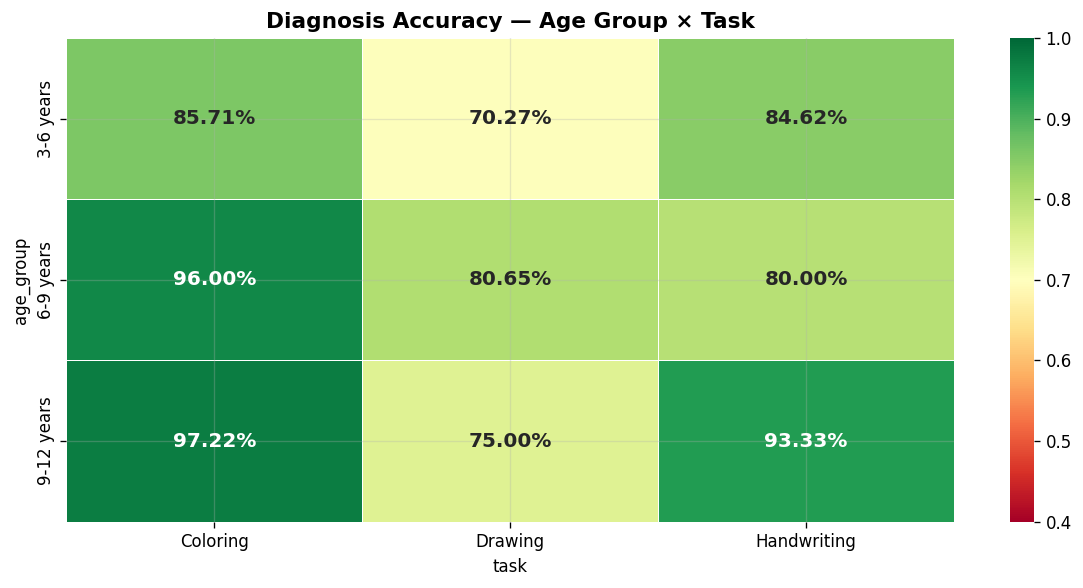

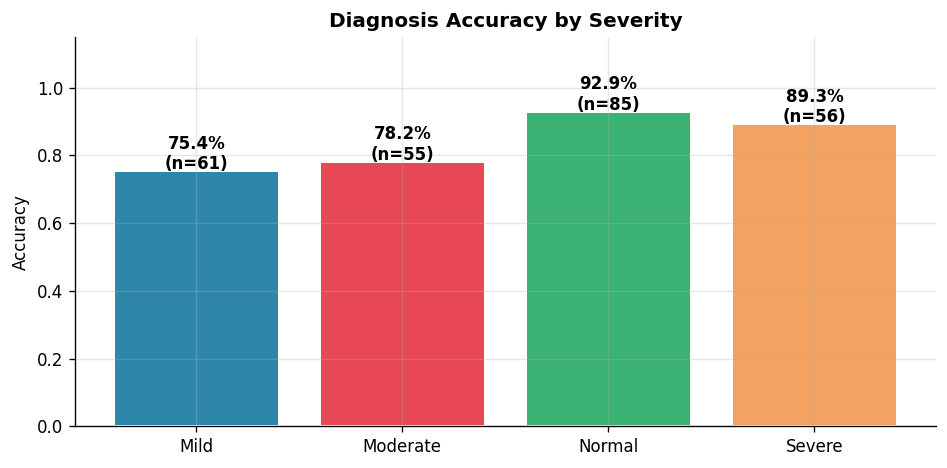

✅ Subgroup analysis complete.


In [ ]:
test_res = test_df.copy().reset_index(drop=True)
test_res["pred_diagnosis"] = le_diag.inverse_transform(y_pred_diag)
test_res["correct"] = (test_res["diagnosis"] == test_res["pred_diagnosis"]).astype(int)

# ── Age × Task accuracy heatmap ───────────────────────────────────────────────
piv = test_res.groupby(["age_group","task"])["correct"].mean().unstack()
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(piv, annot=True, fmt=".2%", cmap="RdYlGn",
            vmin=0.4, vmax=1.0, ax=ax, linewidths=0.5,
            annot_kws={"size":12,"weight":"bold"})
ax.set_title("Diagnosis Accuracy — Age Group × Task", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.savefig(OUT/"12_subgroup_heatmap.png", bbox_inches="tight"); plt.show()

# ── Severity accuracy bar ─────────────────────────────────────────────────────
sev_acc = (test_res.groupby("severity")["correct"]
           .agg(["mean","count"]).rename(columns={"mean":"accuracy","count":"n"}))
fig, ax = plt.subplots(figsize=(8,4))
bars = ax.bar(sev_acc.index, sev_acc["accuracy"],
              color=PAL[:len(sev_acc)], edgecolor="white", linewidth=1.2)
for b, (_, row) in zip(bars, sev_acc.iterrows()):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.005,
            f"{row['accuracy']:.1%}\n(n={int(row['n'])})",
            ha="center", fontsize=10, fontweight="bold")
ax.set_title("Diagnosis Accuracy by Severity", fontweight="bold")
ax.set_ylabel("Accuracy"); ax.set_ylim(0, 1.15)
plt.tight_layout(); plt.savefig(OUT/"13_severity_acc.png", bbox_inches="tight"); plt.show()
print(" Subgroup analysis complete.")

 t-SNE of Fusion Embeddings

Running t-SNE on 257 samples, embedding dim=256 …


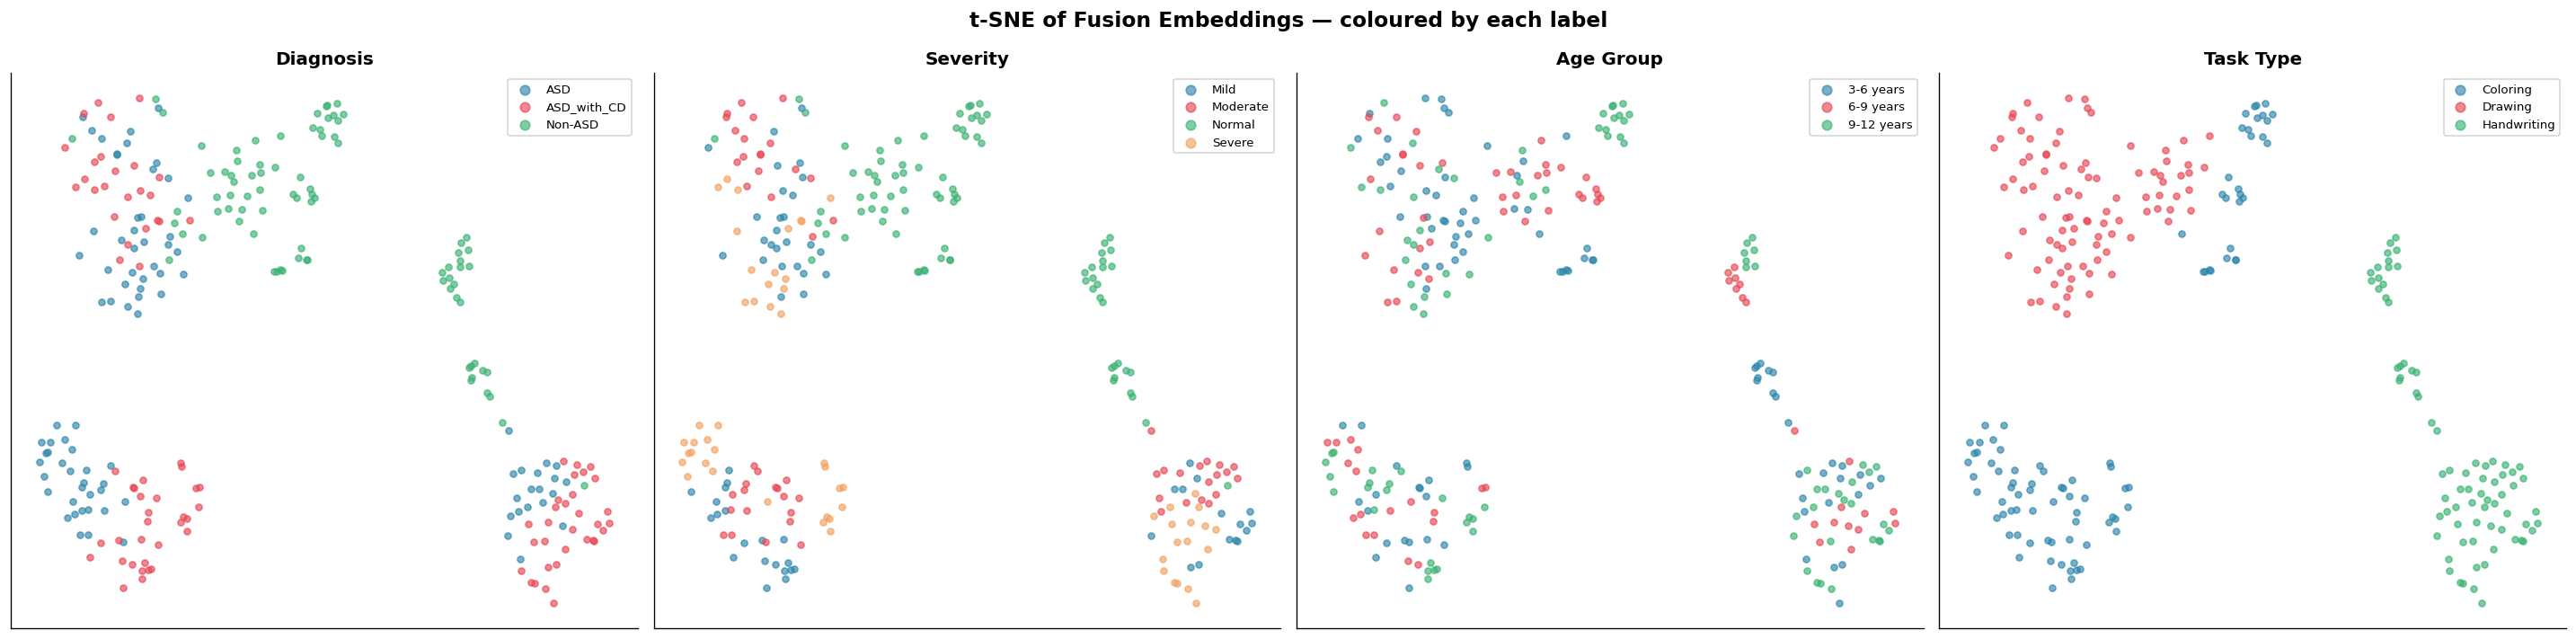

✅ 14_tsne.png


In [ ]:
from sklearn.manifold import TSNE

emb_model = keras.Model(inputs=best_model.inputs,
                         outputs=best_model.get_layer("fuse2").output,
                         name="embedder")

n_tsne = min(500, len(X_rgb_te))
idx    = np.random.choice(len(X_rgb_te), n_tsne, replace=False)
embs   = emb_model.predict([X_rgb_te[idx], X_edge_te[idx], X_tex_te[idx]], verbose=0)

print(f"Running t-SNE on {n_tsne} samples, embedding dim={embs.shape[1]} …")
tsne   = TSNE(n_components=2, perplexity=30, random_state=SEED,
              n_iter=1000, learning_rate="auto", init="pca")
e2d    = tsne.fit_transform(embs)

fig, axes = plt.subplots(1, 4, figsize=(24, 6))
fig.suptitle("t-SNE of Fusion Embeddings — coloured by each label",
             fontsize=14, fontweight="bold")
tsne_labels = [
    ("Diagnosis",  y_true_diag[idx], le_diag),
    ("Severity",   y_true_sev[idx],  le_sev),
    ("Age Group",  y_true_age[idx],  le_age),
    ("Task Type",  y_true_task[idx], le_task),
]
for ax, (title, labs, le) in zip(axes, tsne_labels):
    for ci, cls in enumerate(le.classes_):
        m = labs == ci
        ax.scatter(e2d[m,0], e2d[m,1], label=cls,
                   alpha=0.65, s=18, color=PAL[ci % len(PAL)])
    ax.set_title(title, fontweight="bold"); ax.legend(fontsize=8, markerscale=1.5)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig(OUT/"14_tsne.png", bbox_inches="tight"); plt.show()
print("14_tsne.png")

Grad-CAM Explainability

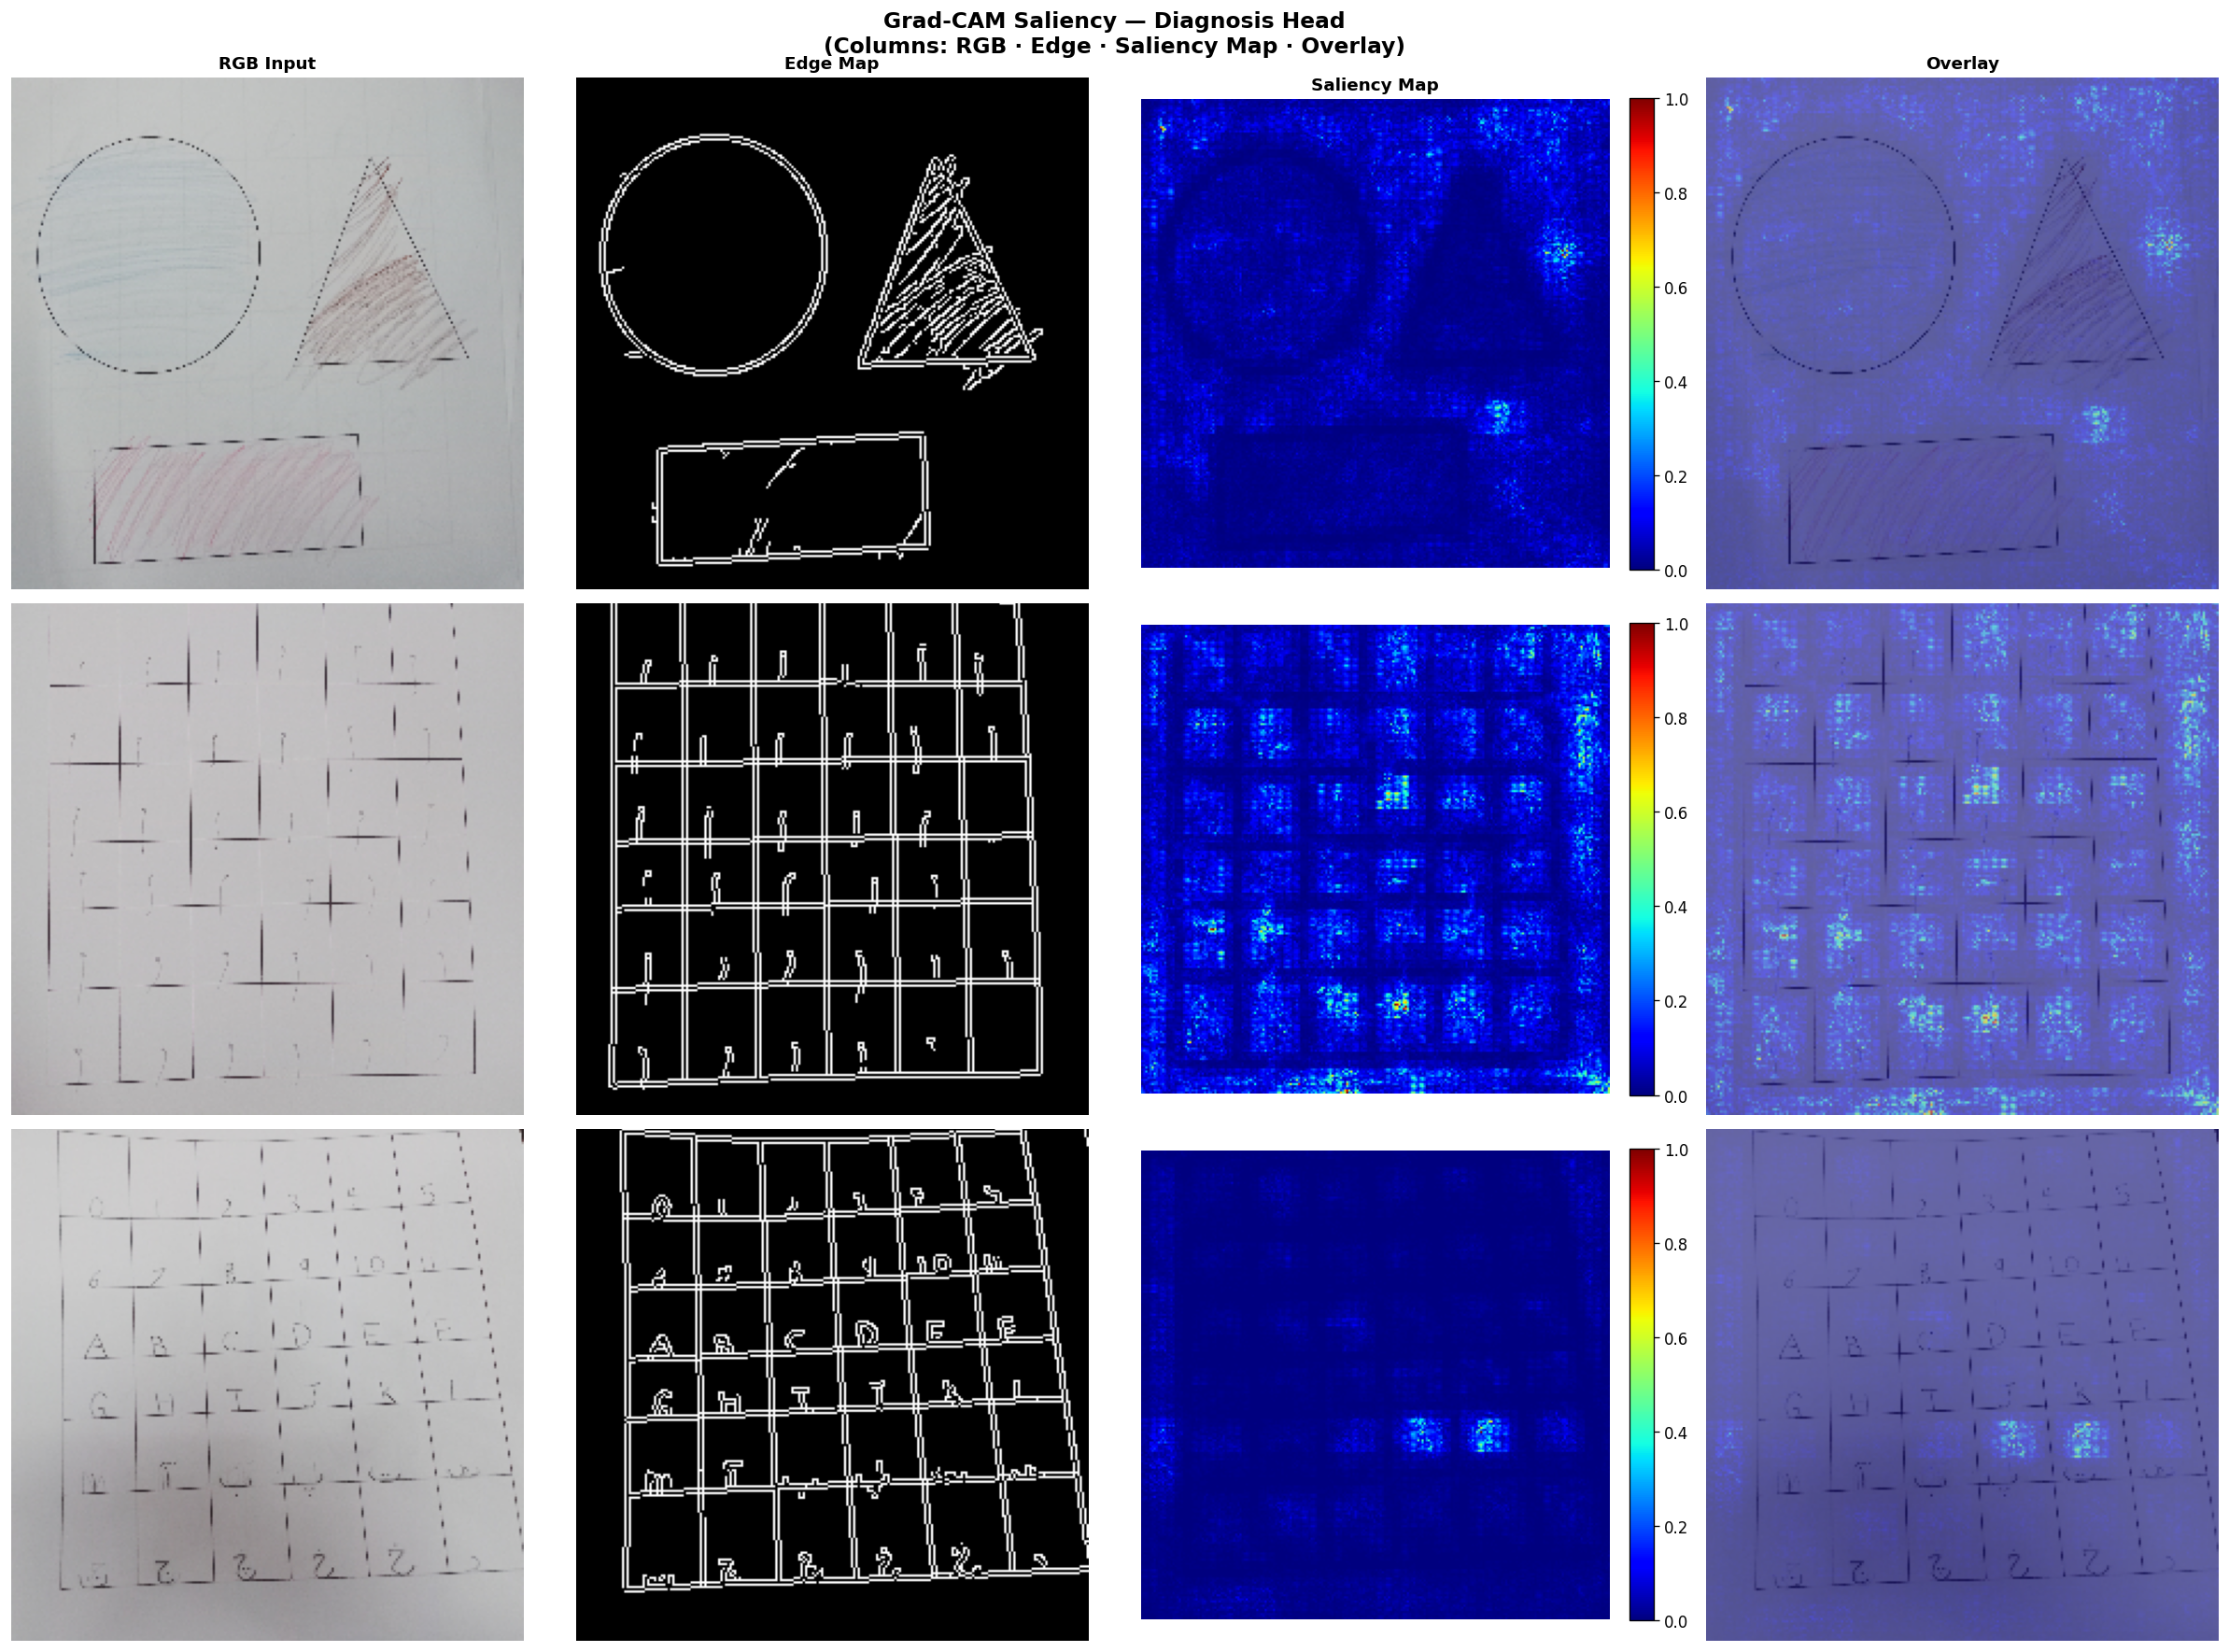

✅ 15_gradcam.png — all 3 diagnosis classes rendered successfully


In [ ]:

# Strategy: use GradientTape on the RGB *input* tensor directly.
# This gives input-gradient saliency maps (equivalent to Grad-CAM at input)
# and works regardless of backbone architecture or layer naming.

def make_gradcam_v2(rgb_pp_batch, edge_batch, tex_batch, pred_index=None):
    """
    Input-gradient saliency map for the diagnosis head.
    Avoids all internal layer access — works with any backbone.

    Args:
        rgb_pp_batch : (1, H, W, 3) preprocessed RGB float32
        edge_batch   : (1, H, W, 1) edge map float32
        tex_batch    : (1, D)       texture vector float32
        pred_index   : class index to explain (None → argmax)
    Returns:
        heatmap      : (H, W) float32 in [0, 1]
        pred_index   : int — predicted class
        confidence   : float — softmax prob for that class
    """
    rgb_t  = tf.Variable(tf.cast(rgb_pp_batch,  tf.float32), trainable=True)
    edge_t = tf.cast(edge_batch, tf.float32)
    tex_t  = tf.cast(tex_batch,  tf.float32)

    with tf.GradientTape() as tape:
        tape.watch(rgb_t)
        preds_list = best_model([rgb_t, edge_t, tex_t], training=False)
        pred_dict  = dict(zip(best_model.output_names, preds_list))
        diag_probs = pred_dict["out_diagnosis"]
        if pred_index is None:
            pred_index = int(tf.argmax(diag_probs[0]).numpy())
        confidence = float(diag_probs[0, pred_index].numpy())
        score      = diag_probs[:, pred_index]

    # Gradient of score w.r.t. RGB input → shape (1, H, W, 3)
    grads = tape.gradient(score, rgb_t)

    # Collapse channels → spatial saliency map
    heatmap = tf.reduce_mean(tf.abs(grads[0]), axis=-1).numpy()  # (H, W)

    # Normalise to [0, 1]
    h_min, h_max = heatmap.min(), heatmap.max()
    if h_max > h_min:
        heatmap = (heatmap - h_min) / (h_max - h_min + 1e-8)
    else:
        heatmap = np.zeros_like(heatmap)

    return heatmap, pred_index, confidence


def overlay_cam(img_uint8, heatmap, alpha=0.50):
    """Blend jet heatmap onto original image."""
    h = cv2.resize(heatmap, (img_uint8.shape[1], img_uint8.shape[0]))
    colored = (plt.cm.jet(h)[:, :, :3] * 255).astype(np.uint8)
    blended = np.clip(img_uint8 * (1 - alpha) + colored * alpha,
                      0, 255).astype(np.uint8)
    return blended


# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
fig.suptitle(
    "Grad-CAM Saliency — Diagnosis Head\n"
    "(Columns: RGB · Edge · Saliency Map · Overlay)",
    fontsize=14, fontweight="bold")
for c, t in enumerate(["RGB Input", "Edge Map",
                        "Saliency Map", "Overlay"]):
    axes[0][c].set_title(t, fontweight="bold", fontsize=11)

errors = []
for r, cls in enumerate(le_diag.classes_):
    sub = test_df[test_df["diagnosis"] == cls]
    if len(sub) == 0:
        for c in range(4): axes[r][c].axis("off")
        continue

    row = sub.sample(1, random_state=SEED).iloc[0]
    rgb_pp, edge, tex = load_and_preprocess(row["path"])

    # Original resized image for display (not preprocessed)
    img_bgr  = cv2.imread(str(row["path"]))
    img_rgb  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_disp = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))  # uint8

    try:
        hmap, pred_cls, conf = make_gradcam_v2(
            rgb_pp[np.newaxis],
            edge[np.newaxis],
            tex[np.newaxis]
        )
        ov      = overlay_cam(img_disp, hmap)
        correct = "OK" if le_diag.classes_[pred_cls] == cls else "WRONG"
        status  = f"{correct} Pred: {le_diag.classes_[pred_cls]} ({conf:.1%})"
    except Exception as ex:
        errors.append(f"{cls}: {ex}")
        hmap   = np.zeros((IMG_SIZE, IMG_SIZE))
        ov     = img_disp
        status = " Error"

    axes[r][0].imshow(img_disp); axes[r][0].axis("off")
    axes[r][0].set_ylabel(cls.replace("_", " "),
                          fontsize=10, fontweight="bold",
                          rotation=0, labelpad=90, va="center")
    axes[r][0].set_xlabel(status, fontsize=9)
    axes[r][1].imshow(edge.squeeze(), cmap="gray"); axes[r][1].axis("off")
    axes[r][2].imshow(hmap, cmap="jet", vmin=0, vmax=1); axes[r][2].axis("off")
    sm = plt.cm.ScalarMappable(cmap="jet", norm=plt.Normalize(0, 1))
    plt.colorbar(sm, ax=axes[r][2], fraction=0.046, pad=0.04)
    axes[r][3].imshow(ov); axes[r][3].axis("off")

plt.tight_layout()
plt.savefig(OUT/"15_gradcam.png", bbox_inches="tight")
plt.show()

if errors:
    print(f"\n {len(errors)} error(s):")
    for e in errors: print(f"   {e}")
else:
    print(" 15_gradcam.png — all 3 diagnosis classes rendered successfully")

Save Model & Single-Image Inference

In [ ]:
import pickle

# Save encoders
with open(OUT/"label_encoders.pkl","wb") as f:
    pickle.dump({"diagnosis":le_diag,"severity":le_sev,"age":le_age,"task":le_task}, f)

# Save model
best_model.save(str(OUT/"ASD_v2_final.keras"))

print(" Saved artefacts:")
for fp in sorted(OUT.iterdir()):
    print(f"   {fp.name:<45} {fp.stat().st_size/1024:>8.1f} KB")

✅ Saved artefacts:
   01_distributions.png                              99.5 KB
   02_heatmap.png                                    56.9 KB
   03_age_diag.png                                   39.2 KB
   04_sample_grid.png                              1762.9 KB
   05_split_balance.png                              64.8 KB
   06_three_modalities.png                          233.8 KB
   07_training_curves.png                           347.0 KB
   08_total_loss.png                                 51.4 KB
   09_confusion_matrices.png                        200.2 KB
   10_roc_pr.png                                     88.0 KB
   11_per_class_f1.png                               82.3 KB
   12_subgroup_heatmap.png                           51.7 KB
   13_severity_acc.png                               33.7 KB
   14_tsne.png                                      134.2 KB
   15_gradcam.png                                  2671.4 KB
   ASD_v2_final.keras                            282595.1 KB
   ar

Demo path: /content/gdrive/MyDrive/ColabNotebooks/NEP2022PROJECTS/ASD/dataset/Non-ASD/Normal/3-6 years/Coloring/IMG20240329145517.jpg


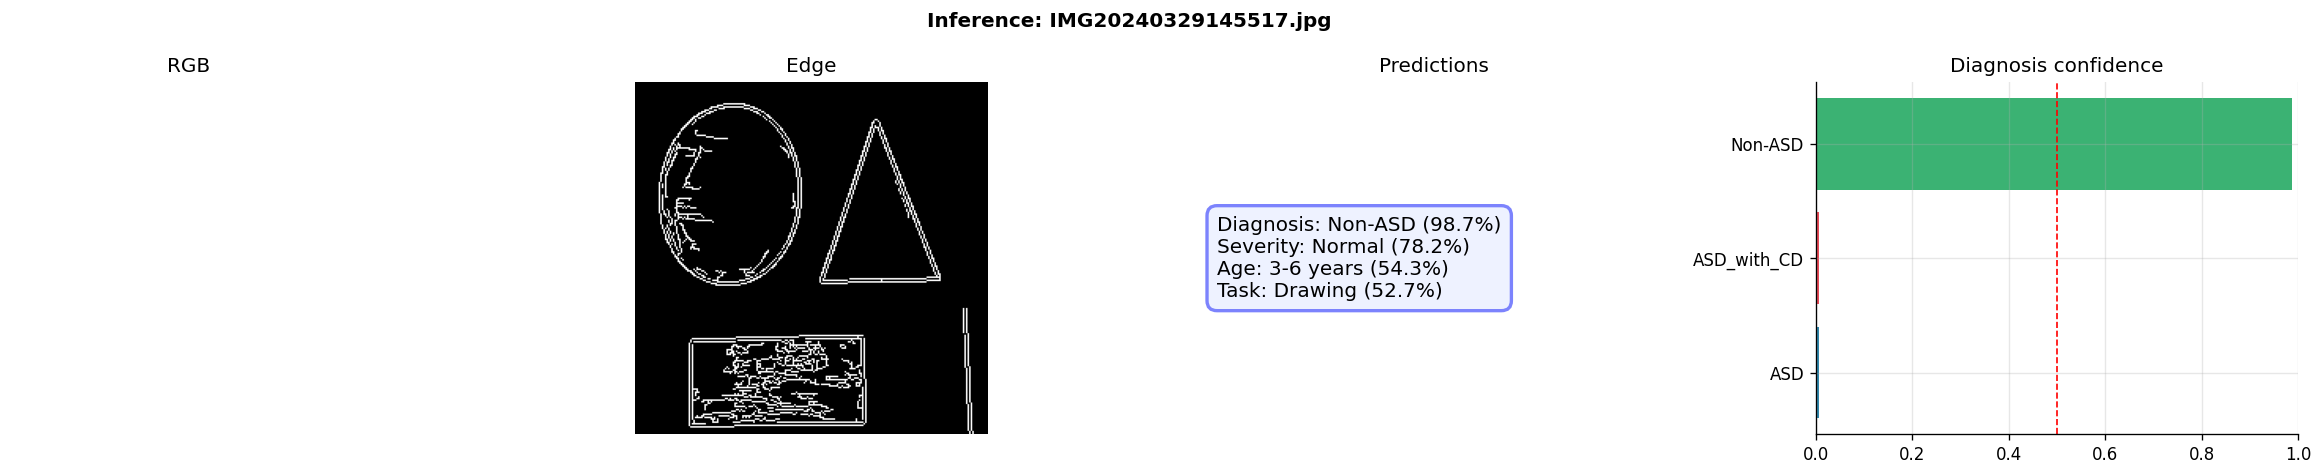

  Diagnosis   : Non-ASD              (98.7%) ✅
  Severity    : Normal               (78.2%) ✅
  Age         : 3-6 years            (54.3%) ✅
  Task        : Drawing              (52.7%) ✅


In [ ]:
def predict_image(image_path):
    """Run all four heads on a single image and display results."""
    rgb_pp, edge, tex = load_and_preprocess(image_path)
    inp = [rgb_pp[None], edge[None], tex[None]]
    preds = best_model.predict(inp, verbose=0)
    pred_d = dict(zip(best_model.output_names, preds))

    results = {}
    for head, le in [("out_diagnosis",le_diag),("out_severity",le_sev),
                      ("out_age",le_age),("out_task",le_task)]:
        probs = pred_d[head][0]
        idx   = np.argmax(probs)
        results[head] = {"label":le.classes_[idx], "conf":float(probs[idx]),
                          "all": dict(zip(le.classes_, probs.tolist()))}

    rgb_disp = np.clip((rgb_pp + 1.0)/2.0, 0, 1)
    fig, axes = plt.subplots(1, 4, figsize=(20,4))
    fig.suptitle(f"Inference: {Path(image_path).name}", fontweight="bold")
    axes[0].imshow(rgb_disp); axes[0].set_title("RGB"); axes[0].axis("off")
    axes[1].imshow(edge.squeeze(), cmap="gray")
    axes[1].set_title("Edge"); axes[1].axis("off")

    text = "\n".join([f"{k.replace('out_','').capitalize()}: "
                       f"{v['label']} ({v['conf']:.1%})"
                       for k, v in results.items()])
    axes[2].text(0.05, 0.5, text, transform=axes[2].transAxes, fontsize=12,
                 va="center",
                 bbox=dict(boxstyle="round,pad=0.5",fc="#EEF2FF",ec="#7C83FD",lw=2))
    axes[2].axis("off"); axes[2].set_title("Predictions")

    diag_probs = results["out_diagnosis"]["all"]
    axes[3].barh(list(diag_probs.keys()), list(diag_probs.values()),
                 color=PAL[:len(diag_probs)])
    axes[3].axvline(0.5, color="red", ls="--", lw=1)
    axes[3].set_xlim(0,1); axes[3].set_title("Diagnosis confidence")

    plt.tight_layout(); plt.show()

    for k, v in results.items():
        flag = " Low conf" if v["conf"] < 0.5 else "TICK"
        print(f"  {k.replace('out_','').capitalize():<12}: {v['label']:<20} ({v['conf']:.1%}) {flag}")
    return results

# ── Demo on first test image ───────────────────────────────────────────────────
print(f"Demo path: {test_df['path'].iloc[0]}")
_ = predict_image(test_df["path"].iloc[0])